In [1]:
import os
import polars as pl
import pandas as pd
import numpy as np
import re
import html

BASE_PATH = "/kaggle/input/datasets/brdh7940/vietnamese-legal-documents-cleaned"

CONTENT_PATH = f"{BASE_PATH}/content.parquet"
META_PATH = f"{BASE_PATH}/metadata.parquet"
REL_PATH = f"{BASE_PATH}/relationships.parquet"

['relationships.parquet', 'content.parquet', 'metadata.parquet']


# 1. Load Dataset

In [21]:
content = pl.read_parquet(CONTENT_PATH)
metadata = pl.read_parquet(META_PATH)
relationships = pl.read_parquet(REL_PATH)

print("content:", content.shape)
print("metadata:", metadata.shape)
print("relationships:", relationships.shape)

content: (353746, 3)
metadata: (353746, 18)
relationships: (138656, 3)


In [22]:
# Preprocessing – Lọc độ dài và clean OCR

def clean_ocr(s: str) -> str:
    s = str(s)
    s = re.sub(r"\s+", " ", s)
    s = re.sub(r"\s+([,.;:])", r"\1", s)

    fixes = {
        "S Ố": "SỐ", "T ÊN": "TÊN", "TH Ủ": "THỦ", "H ÀNH": "HÀNH",
        "TH Ể": "THỂ", "TRUY Ề N": "TRUYỀN", "M Ô I": "MÔI",
        "N Ô NG": "NÔNG", "T À I": "TÀI", "K Ế": "KẾ", "D Ự NG": "DỰNG",
        "đ ể": "để", "đ ă ng": "đăng", "t ả i": "tải",
        "c ấ p": "cấp", "gi ấ y": "giấy", "ch ứ ng": "chứng",
        "qu y ền": "quyền", "đ ị a": "địa", "h oạt": "hoạt",
        "đ ộ ng": "động", "cơ s ở": "cơ sở", "yếu t ố": "yếu tố",
        "nh ư ng": "nhưng", "Ủ y": "Ủy", "Ủ y ban": "Ủy ban"
    }
    for k, v in fixes.items():
        s = s.replace(k, v)

    return s.strip()

# Lọc content có độ dài >= 20 ký tự
content_filtered = content.with_columns(
    pl.col('content').str.len_chars().alias('char_len')
).filter(pl.col('char_len') >= 20).drop('char_len')

print(f"Content trước lọc: {content.height} hàng")
print(f"Content sau lọc (>=20 chars): {content_filtered.height} hàng")

# Lọc metadata chỉ giữ các id còn trong content_filtered
valid_ids = content_filtered['id'].to_list()
metadata_filtered = metadata.filter(pl.col('id').is_in(valid_ids))

# Lọc relationships: giữ các dòng mà cả doc_id và other_doc_id đều tồn tại
relationships_filtered = relationships.filter(
    pl.col('doc_id').is_in(valid_ids) & pl.col('other_doc_id').is_in(valid_ids)
)

print(f"Metadata trước lọc: {metadata.height} hàng, sau lọc: {metadata_filtered.height} hàng")
print(f"Relationships trước lọc: {relationships.height} hàng, sau lọc: {relationships_filtered.height} hàng")

# Áp dụng clean_ocr cho cột content
content_clean = content_filtered.with_columns(
    pl.col('content').map_elements(clean_ocr, return_dtype=pl.String).alias('content')
)

# Ghi đè
content = content_clean
metadata = metadata_filtered
relationships = relationships_filtered

Content trước lọc: 353746 hàng
Content sau lọc (>=20 chars): 353739 hàng
Metadata trước lọc: 353746 hàng, sau lọc: 353739 hàng
Relationships trước lọc: 138656 hàng, sau lọc: 138629 hàng
Hoàn tất preprocessing. Các biến content, metadata, relationships đã được cập nhật.


# 2. Chunking

In [34]:
import re
import uuid
import hashlib
from dataclasses import dataclass
from typing import Any, Dict, List, Optional, Tuple

# ============================================================
# 1. CONFIG
# ============================================================

@dataclass
class ChunkingConfig:
    min_chars: int = 300
    target_chars: int = 1600
    max_chars: int = 2200
    hard_max_chars: int = 3000

    overlap_chars: int = 150          # chỉ prose khi split Điều/khoản dài
    table_max_chars: int = 2000
    table_row_mode_threshold: int = 2500  # bảng > ngưỡng này → split từng row
    short_doc_threshold: int = 300

    max_context_prefix_chars: int = 500
    max_section_title_chars: int = 180

    parse_procedure_tables: bool = True

    # Long prose splitting (article/block > threshold → hierarchical split)
    long_prose_threshold: int = 3000     # chars > này với prose block → split tiếp
    long_prose_target_chars: int = 1400  # target khi hierarchical split (800–1800)
    long_prose_max_chars: int = 2500     # hard max sau hierarchical split
    table_summary_threshold: int = 3000  # bảng > này → table_summary + raw_table
    table_summary_max_chars: int = 1000  # cap độ dài table_summary (embed target)
    table_summary_max_columns: int = 12   # OCR 1 hàng nhiều cột — không liệt kê hết


CONFIG = ChunkingConfig()


# ============================================================
# 2. REGEX HELPERS
# ============================================================

RE_WHITESPACE = re.compile(r"[ \t]+")
RE_MULTI_NEWLINE = re.compile(r"\n{3,}")

RE_APPENDIX = re.compile(
    r"^\s*(PHỤ\s+LỤC|Phụ\s+lục)\s*([IVXLCDM]+|\d+)?(?:\s*[:.\-–]\s*(.*))?$",
    re.IGNORECASE
)
RE_PART = re.compile(
    r"^\s*(PHẦN|Phần)\s+([IVXLCDM]+|\d+)(?:\s*[:.\-–]\s*(.*))?$",
    re.IGNORECASE
)
RE_CHAPTER = re.compile(
    r"^\s*(CHƯƠNG|Chương)\s+([IVXLCDM]+|\d+)(?:\s*[:.\-–]\s*(.*))?$",
    re.IGNORECASE
)
RE_SECTION = re.compile(
    r"^\s*(MỤC|Mục)\s+([IVXLCDM]+|\d+)(?:\s*[:.\-–]\s*(.*))?$",
    re.IGNORECASE
)
RE_ARTICLE = re.compile(
    r"^\s*(ĐIỀU|Điều)\s+(\d+[a-zA-Z]?)\s*[\.:]?\s*(.*)$",
    re.IGNORECASE
)
RE_CLAUSE = re.compile(r"^\s*(\d+)\.\s+")

# Roman numeral section headers inside long articles (e.g. fee-schedule tables extracted
# without pipe separators).  Only uppercase to avoid false matches on content words.
# Matches: "II Chi cho..." or "VIII\n..." (standalone numeral on its own line).
_ROMAN = r"(?:XIV|XIII|XII|XIX|XVIII|XVII|XVI|XV|XI|IX|VIII|VII|VI|IV|III|II|XX|X|V)"
RE_ROMAN_SECTION_INLINE = re.compile(rf"^\s*({_ROMAN})\s+[A-ZÀ-Ỵ]")
RE_ROMAN_SECTION_STANDALONE = re.compile(rf"^\s*({_ROMAN})\s*$")

RE_FOOTER = re.compile(
    r"(?is)(?:^|\s)(Nơi\s+nhận\s*[:\-].*)$",
)

# Embedded sub-document headers (e.g. attached regulations/bylaws inside a Nghị quyết).
# Treated as "part"-level heading so subsequent Điều numbers get a disambiguated section_path.
RE_REGULATION_BLOCK = re.compile(
    r"^\s*(QUY\s*ĐỊNH|QUY\s*CHẾ|NỘI\s*QUY|ĐIỀU\s*LỆ|QUY\s*TẮC"
    r"|BẢNG\s*GIÁ|DANH\s*MỤC|PHƯƠNG\s*ÁN|ĐỀ\s*ÁN|CHƯƠNG\s*TRÌNH)\s*$",
    re.IGNORECASE,
)

# Khối văn bản đính kèm (QUY ĐỊNH kèm Nghị quyết, …) — dùng khi gộp header với Điều đầu.
REGULATION_PART_IDS = frozenset({
    "QUY ĐỊNH", "QUY CHẾ", "NỘI QUY", "ĐIỀU LỆ", "QUY TẮC",
    "BẢNG GIÁ", "DANH MỤC", "PHƯƠNG ÁN", "ĐỀ ÁN", "CHƯƠNG TRÌNH",
})

# Điều không ở đầu dòng (OCR): "...HĐND)\n. Điều 2. Phạm vi..."
RE_INLINE_ARTICLE_AFTER_NEWLINE = re.compile(
    r"\n\s*\.\s*(Điều\s+\d+[a-zA-Z]?)\s*([\.\:])\s*",
    re.IGNORECASE,
)
RE_INLINE_ARTICLE_AFTER_PAREN = re.compile(
    r"(?<=[)])\s*\.\s+(Điều\s+\d+[a-zA-Z]?)\s*([\.\:])\s*",
    re.IGNORECASE,
)
# OCR: "QUYẾT ĐỊNH: Điều 1. Phê duyệt..." — tiêu đề kết luận + Điều trên cùng dòng
RE_INLINE_ARTICLE_AFTER_COLON = re.compile(
    r"(?<=[:\：])\s+(Điều\s+\d+[a-zA-Z]?)\s*([\.\:])\s*",
    re.IGNORECASE,
)
# OCR một dòng: "...đính kèm. Điều 2. Sở Nông nghiệp..."
RE_INLINE_ARTICLE_AFTER_PERIOD = re.compile(
    r"(?<=\.)\s+(Điều\s+\d+[a-zA-Z]?)\s*([\.\:])\s*",
    re.IGNORECASE,
)

RE_ANNEX_BLOCK_START = re.compile(
    r"\b(DANH\s+MỤC|PHỤ\s+LỤC"
    r"|ĐỀ\s+ÁN|ĐIỀU\s+LỆ|QUY\s+CHẾ|NỘI\s+QUY"
    r"|Biểu\s+số\s+\d+)\b",
    re.IGNORECASE,
)

# Footer trên cùng dòng với thân văn bản (không có xuống dòng trước "Nơi nhận")
RE_FOOTER_INLINE = re.compile(
    r"(?<=[./])\s+(Nơi\s+nhận\s*[:\-])",
    re.IGNORECASE,
)

# Bắt đầu lưới bảng pipe OCR: "| 1 |", "| A | Lĩnh vực", ...
RE_PIPE_GRID_ROW = re.compile(
    r"\s+\|\s+(?:\d{1,4}|[IVXLCDM]{1,6}|[A-ZÀ-Ỵ])\s+\|",
    re.IGNORECASE,
)

# Khoản Arabic đầu dòng / inline (Chỉ thị, Nghị quyết không có Điều: 1. … 2. … 3. …)
RE_NUMBERED_CLAUSE_HEADING = re.compile(r"^\s*(\d{1,2})\.\s+(.{3,})$")
RE_NUMBERED_CLAUSE_BODY_START = re.compile(r"^[A-ZÀ-ỴĐ]")
RE_INLINE_NUMBERED_CLAUSE = re.compile(
    r"(?<=[.;:\)）])\s+(\d{1,2})\.\s+(?=[A-ZÀ-ỴĐ])",
)

# Điểm a) b) c) đầu dòng trong khoản (chữ thường kể cả đ, sau normalize)
RE_DIEM_START = re.compile(r"(?m)(?=^[ \t]*[a-zđ][)\.]\s)", re.UNICODE)
# Nhận diện văn bản có cấu trúc luật (Điều, Chương) — dùng để detect appendix sub-doc
RE_HAS_ARTICLE_MARKER = re.compile(
    r"(?m)^\s*(ĐIỀU|Điều)\s+\d+|^\s*(CHƯƠNG|Chương)\s+[IVXLCDM\d]",
    re.IGNORECASE,
)


# ============================================================
# 2b. GENERALIZABLE CONSTANTS  (mở rộng tại đây, không sửa logic)
# ============================================================

# --------------- Tách câu ---------------
# Viết tắt hỗn hợp hoa-thường / 1 ký tự: không bị bảo vệ bởi auto-protect ALLCAPS.
# Viết tắt ALLCAPS ≥2 ký tự (UBND, TW, CP, NĐ, QĐ, HĐND, …) được bảo vệ tự động
# bởi _RE_AUTO_ABBREV bên dưới — không cần liệt kê ở đây.
_SENTENCE_SPLIT_PROTECTED: Dict[str, str] = {
    # Đơn vị hành chính 1 ký tự
    "P.": "P<dot>",
    "Q.": "Q<dot>",
    "H.": "H<dot>",
    # Học hàm / học vị hỗn hợp hoa-thường
    "ThS.": "ThS<dot>",
    "PGS.": "PGS<dot>",
    "TS.": "TS<dot>",
    "GS.": "GS<dot>",
    "BS.": "BS<dot>",
    "KS.": "KS<dot>",
    "CN.": "CN<dot>",
    "LS.": "LS<dot>",
    # Viết tắt thông dụng hỗn hợp / nhiều dấu chấm
    "v.v.": "vv<dot>",
    "v.v": "vv2<dot>",
    "Đ/c.": "Dc<dot>",
}

# Bảo vệ tự động mọi chuỗi ALLCAPS ≥2 ký tự trước dấu chấm (UBND., TW., NĐ., …).
# [A-ZÀ-Ỵ] bao gồm ASCII uppercase + toàn bộ uppercase có dấu tiếng Việt (Đ, Ă, Ơ, …).
_RE_AUTO_ABBREV = re.compile(r"([A-ZÀ-Ỵ]{2,})\.")
_AUTO_ABBREV_PH = "<adot>"   # placeholder khác với <dot> để tránh collision khi restore

# Khoản đánh số 1. 2. 3. — không cắt tại dấu chấm khi split câu (Chỉ thị, Nghị quyết, …).
_CLAUSE_NUMBER_PH = "<cdot>"
_RE_CLAUSE_NUMBER = re.compile(r"(\b\d{1,2})\.\s+(?=[A-ZÀ-ỴĐ])")

# --------------- Chữ ký cuối văn bản ---------------
# Thêm chức danh mới tại đây mà không cần sửa _extract_footer.
_SIG_PATTERNS: List[str] = [
    r"\bKT\.\s+",
    r"\bTM\.\s+",
    r"\bCHỦ\s+TỊCH\b",
    r"\bPHÓ\s+CHỦ\s+TỊCH\b",
    r"\bBỘ\s+TRƯỞNG\b",
    r"\bTHỨ\s+TRƯỞNG\b",
    r"\bTỔNG\s+GIÁM\s+ĐỐC\b",
    r"\bGIÁM\s+ĐỐC\b",
    r"\bPHÓ\s+GIÁM\s+ĐỐC\b",
    r"\bTỔNG\s+CỤC\s+TRƯỞNG\b",
    r"\bCỤC\s+TRƯỞNG\b",
    r"\bVỤ\s+TRƯỞNG\b",
    r"\bCHÁNH\s+VĂN\s+PHÒNG\b",
    r"\bTRƯỞNG\s+BAN\b",
    r"\bHIỆU\s+TRƯỞNG\b",
    r"\bTRƯỞNG\s+PHÒNG\b",
    r"\bVIỆN\s+TRƯỞNG\b",
    r"\bCHÁNH\s+ÁN\b",
    r"\bTHỦ\s+TRƯỞNG\b",
    r"\bTRƯỞNG\s+CƠ\s+QUAN\b",
]

# --------------- Bảng thủ tục hành chính (TTHC) ---------------
# Từ khóa nhận diện bảng TTHC — thêm loại bảng mới tại đây.
_TTHC_DETECT_KEYWORDS: frozenset = frozenset({
    "thủ tục hành chính", "tên thủ tục", "tthc",
})
# Từ khóa nhận diện hàng tiêu đề bảng TTHC.
_TTHC_HEADER_KEYWORDS: frozenset = frozenset({
    "thủ tục", "tên thủ tục", "số tt", "số thứ tự",
})
# Từ khóa nhận diện hàng header/separator cần bỏ qua khi parse record.
_TTHC_HEADER_REJECT_KEYWORDS: frozenset = frozenset({
    "tên thủ tục", "số tt", "ghi chú", "số thứ tự",
})
# Pattern nhận diện cột phân nhóm lĩnh vực trong bảng (sub-field rows).
_TABLE_SUBFIELD_PATTERNS: List[str] = [
    r"(Lĩnh\s+vực\s*[:\-]?\s*.+)",
    r"(Ngành\s*[:\-]?\s*.+)",
]

# --------------- Tiêu đề nhóm trong phụ lục ---------------
# Từ khóa phân biệt dòng heading nhóm lĩnh vực (I. LĨNH VỰC TƯ PHÁP)
# với dòng dữ liệu bình thường khi cả hai đều bắt đầu bằng Roman numeral.
# Thêm domain keyword mới tại đây.
_APPENDIX_HEADING_KEYWORDS: frozenset = frozenset({
    "TTHC", "LĨNH VỰC", "NHÓM LĨNH VỰC", "THỦ TỤC HÀNH CHÍNH",
    "NGÀNH", "PHÂN NHÓM", "LOẠI",
})

# --------------- Retrieval index flags ---------------
# Chunk types KHÔNG embed vào dense vector index.
_NO_EMBED_TYPES: frozenset = frozenset({
    "raw_table", "signature", "distribution_list",
})
# Chunk types KHÔNG index BM25/keyword search.
_NO_BM25_TYPES: frozenset = frozenset({
    "signature", "distribution_list",
})


def get_retrieval_flags(chunk_type: str) -> Tuple[bool, bool]:
    """Trả về (embed, keyword_index) cho chunk_type đã cho."""
    return (
        chunk_type not in _NO_EMBED_TYPES,
        chunk_type not in _NO_BM25_TYPES,
    )


# ============================================================
# 3. NORMALIZER
# ============================================================

class LegalTextNormalizer:
    @staticmethod
    def normalize(text: str) -> str:
        if not text:
            return ""

        text = text.replace("\r\n", "\n").replace("\r", "\n")
        text = text.replace("\u00a0", " ")
        text = text.replace("−", "-").replace("–", "-").replace("—", "-")

        lines = []
        for line in text.split("\n"):
            line = RE_WHITESPACE.sub(" ", line).strip()
            lines.append(line)

        text = "\n".join(lines)
        text = RE_MULTI_NEWLINE.sub("\n\n", text)

        # Chuẩn hóa khoảng trắng quanh dấu pipe để parser bảng ổn hơn.
        text = re.sub(r"\s*\|\s*", " | ", text)
        text = re.sub(r"[ \t]{2,}", " ", text)

        text = LegalTextNormalizer._explode_mixed_prose_and_tables(text)
        text = LegalTextNormalizer._explode_flattened_pipe_tables(text)
        text = LegalTextNormalizer._explode_inline_articles(text)
        text = LegalTextNormalizer._explode_inline_numbered_clauses(text)

        return text.strip()

    @staticmethod
    def _explode_mixed_prose_and_tables(text: str) -> str:
        """Tách phụ lục/danh mục, footer và lưới bảng khỏi thân văn bản trên cùng một dòng OCR."""
        text = RE_FOOTER_INLINE.sub(r"\n\1", text)

        def split_annex(m: re.Match) -> str:
            return "\n" + m.group(0)

        text = re.sub(
            r"(?<=[)])\s+(?=(?:DANH\s+MỤC|PHỤ\s+LỤC)\b)",
            split_annex,
            text,
            flags=re.IGNORECASE,
        )
        text = re.sub(
            r"(?<=\.)\s+(?=(?:DANH\s+MỤC|PHỤ\s+LỤC)\b)",
            split_annex,
            text,
            flags=re.IGNORECASE,
        )

        new_lines: List[str] = []
        for line in text.split("\n"):
            if (
                len(line) > 400
                and line.count("|") >= 3
                and _line_has_legal_prose_markers(line)
            ):
                grid = RE_PIPE_GRID_ROW.search(line)
                annex = RE_ANNEX_BLOCK_START.search(line)
                split_at = None
                if annex and annex.start() > 80:
                    split_at = annex.start()
                elif grid and grid.start() > 80:
                    split_at = grid.start()
                if split_at is not None:
                    head = line[:split_at].strip()
                    tail = line[split_at:].strip()
                    if head:
                        new_lines.append(head)
                    if tail:
                        new_lines.append(tail)
                    continue
            new_lines.append(line)
        return "\n".join(new_lines)

    @staticmethod
    def _explode_inline_articles(text: str) -> str:
        """Tách Điều nằm giữa đoạn (sau dấu chấm / xuống dòng / dấu hai chấm) thành dòng heading riêng."""
        text = RE_INLINE_ARTICLE_AFTER_COLON.sub(r"\n\1\2 ", text)
        text = RE_INLINE_ARTICLE_AFTER_PERIOD.sub(r"\n\1\2 ", text)
        text = RE_INLINE_ARTICLE_AFTER_NEWLINE.sub(r"\n\1\2 ", text)
        text = RE_INLINE_ARTICLE_AFTER_PAREN.sub(r"\n\1\2 ", text)
        return text

    @staticmethod
    def _explode_inline_numbered_clauses(text: str) -> str:
        """Tách khoản 1. 2. 3. nằm giữa đoạn (OCR một dòng) thành dòng riêng."""
        return RE_INLINE_NUMBERED_CLAUSE.sub(r"\n\1. ", text)

    @staticmethod
    def _explode_flattened_pipe_tables(text: str) -> str:
        new_lines = []
        for line in text.split("\n"):
            if len(line) > 800 and line.count("|") >= 12:
                s = line
                s = re.sub(
                    r"\s+\|\s*(?=(?:\d{1,4}|[IVXLCDM]{1,6}\.|[A-ZÀ-Ỵ]\.)\s*\|)",
                    "\n| ",
                    s
                )
                s = re.sub(
                    rf"\s+(?=(?:PHỤ\s+LỤC|{_ROMAN}\.)\s+[A-ZÀ-Ỵ])",
                    "\n",
                    s
                )
                new_lines.extend([x.strip() for x in s.split("\n") if x.strip()])
            else:
                new_lines.append(line)
        return "\n".join(new_lines)


# ============================================================
# 4. DOCUMENT METADATA (from metadata.parquet, join by doc id)
# ============================================================

METADATA_PREFIX_FIELDS = (
    "title",
    "legal_type",
    "document_number",
    "issuing_authority",
    "issuance_date",
    "effect_status",
    "linh_vuc",
)


def coerce_document_metadata(record: Optional[Dict[str, Any]]) -> Dict[str, Any]:
    """Chuẩn hóa một dòng metadata.parquet cho prefix ngữ cảnh khi embed."""
    if not record:
        return {}
    out: Dict[str, Any] = {}
    for key in METADATA_PREFIX_FIELDS:
        val = record.get(key)
        if val is not None and str(val).strip():
            out[key] = str(val).strip()
    return out


def metadata_lookup_from_dataframe(metadata_df, id_col: str = "id") -> Dict[Any, Dict[str, Any]]:
    """Map doc id → metadata dict (Polars hoặc pandas DataFrame)."""
    try:
        records = metadata_df.to_dicts()
    except AttributeError:
        records = metadata_df.to_dict(orient="records")
    return {rec[id_col]: coerce_document_metadata(rec) for rec in records}


# ============================================================
# 5. UTILS
# ============================================================

def stable_hash(value: str, length: int = 16) -> str:
    return hashlib.sha1(value.encode("utf-8")).hexdigest()[:length]


def make_uuid() -> str:
    return str(uuid.uuid4())


def truncate(value: Optional[str], max_len: int) -> Optional[str]:
    if value is None:
        return None
    value = re.sub(r"\s+", " ", value).strip()
    if len(value) <= max_len:
        return value
    return value[:max_len - 3] + "..."


def _pipe_line_stats(line: str) -> Tuple[int, float, int]:
    """(pipe_count, avg_segment_len, max_segment_len)"""
    segments = [seg.strip() for seg in line.split("|") if seg.strip()]
    if not segments:
        return line.count("|"), float(len(line)), len(line)
    lengths = [len(seg) for seg in segments]
    return line.count("|"), sum(lengths) / len(lengths), max(lengths)


def _line_has_legal_prose_markers(line: str) -> bool:
    """Đánh dấu thân văn bản — không khớp 'Quyết định' trong tên thủ tục bảng."""
    if re.search(r"\b(Điều\s+\d+[a-zA-Z]?|Căn\s+cứ)\b", line, re.IGNORECASE):
        return True
    return bool(
        re.search(
            r"(?:^|[.;:]\s*)"
            r"(QUYẾT\s*ĐỊNH|CHỈ\s*THỊ|NGHỊ\s*QUYẾT|THÔNG\s*TƯ|CÔNG\s*VĂN)\b",
            line,
            re.IGNORECASE,
        )
    )


def _is_pipe_grid_row(line: str) -> bool:
    """Hàng lưới OCR: | STT | nội dung | ..."""
    s = line.strip()
    if s.count("|") < 2:
        return False
    return bool(
        re.match(
            r"^\|?\s*(?:\d{1,4}|[IVXLCDM]{1,6}|[A-ZÀ-Ỵ])\s+\|",
            s,
            re.IGNORECASE,
        )
    )


def is_probably_table_line(line: str) -> bool:
    s = line.strip()
    if not s:
        return False

    if re.search(r"\bSỐ\s*TT\b", s, re.IGNORECASE) and re.search(
        r"\bTHỦ\s*TỤC\b", s, re.IGNORECASE
    ):
        return True

    if _is_pipe_grid_row(s):
        return True

    pipe_count, avg_segment_len, max_segment_len = _pipe_line_stats(s)
    if pipe_count < 2:
        return False

    # Letterhead / chữ ký: ít cột pipe, có đoạn prose dài — không phải hàng bảng.
    if pipe_count <= 8 and max_segment_len > 150:
        return False

    # Thân văn bản (Điều, căn cứ, …) lẫn vài pipe letterhead — giữ prose.
    if _line_has_legal_prose_markers(s) and pipe_count <= 10 and max_segment_len > 80:
        return False

    # Lưới bảng OCR: nhiều pipe hoặc ô ngắn đều nhau.
    if pipe_count >= 6 and avg_segment_len <= 120:
        return True
    if pipe_count >= 10:
        return True

    if avg_segment_len > 200:
        return False

    return pipe_count >= 2 and avg_segment_len <= 200


def split_sentences_vi(text: str) -> List[str]:
    s = text
    # Bước 1: bảo vệ viết tắt hỗn hợp / 1 ký tự trong danh sách tường minh.
    for k, v in _SENTENCE_SPLIT_PROTECTED.items():
        s = s.replace(k, v)
    # Bước 2: bảo vệ tự động mọi chuỗi ALLCAPS ≥2 ký tự trước dấu chấm
    # (UBND., TW., CP., NĐ., HĐND., VKSND., … — không cần liệt kê từng cái).
    s = _RE_AUTO_ABBREV.sub(r"\1" + _AUTO_ABBREV_PH, s)
    # Bước 3: bảo vệ khoản đánh số (1. Chủ tịch …) — tránh cắt sau "1."
    s = _RE_CLAUSE_NUMBER.sub(r"\1" + _CLAUSE_NUMBER_PH + " ", s)

    parts = re.split(r"(?<=[.!?;:])\s+(?=[A-ZÀ-Ỵ0-9Đ])", s)
    out = []
    for p in parts:
        # Khôi phục bước 1
        for k, v in _SENTENCE_SPLIT_PROTECTED.items():
            p = p.replace(v, k)
        # Khôi phục bước 2
        p = p.replace(_AUTO_ABBREV_PH, ".")
        # Khôi phục bước 3
        p = p.replace(_CLAUSE_NUMBER_PH, ".")
        p = p.strip()
        if p:
            out.append(p)
    return out


def is_orphan_amount_line(line: str) -> bool:
    """Dòng chỉ là mức tiền (đuôi bảng biểu OCR) — không dùng làm overlap."""
    s = line.strip()
    if not s:
        return False
    if re.fullmatch(r"-?[\d.,]+\s*000(?:\.\d{3})*", s):
        return True
    if re.fullmatch(r"-?[\d.,]{4,18}", s) and "." in s:
        return True
    return False


def strip_leading_orphan_amounts(text: str) -> str:
    lines = text.split("\n")
    while lines and is_orphan_amount_line(lines[0]):
        lines.pop(0)
    return "\n".join(lines).strip()


def strip_trailing_orphan_amounts(text: str) -> str:
    lines = text.split("\n")
    while lines and is_orphan_amount_line(lines[-1]):
        lines.pop()
    return "\n".join(lines).strip()


def clauses_use_roman_sections(clauses: List[str]) -> bool:
    for clause in clauses:
        first = clause.split("\n", 1)[0].strip()
        if RE_ROMAN_SECTION_INLINE.match(first) or RE_ROMAN_SECTION_STANDALONE.match(first):
            return True
    return False


def smart_overlap(text: str, max_chars: int) -> str:
    if len(text) <= max_chars:
        return text

    tail = text[-max_chars:]

    candidates = [
        tail.rfind("\n"),
        tail.rfind(". "),
        tail.rfind("; "),
        tail.rfind(": "),
    ]
    idx = max(candidates)
    if idx >= 40:
        return tail[idx + 1:].strip()

    space_idx = tail.find(" ")
    if space_idx != -1:
        return tail[space_idx + 1:].strip()
    return tail.strip()


def normalize_heading_id(kind: str, number: Optional[str]) -> str:
    if number:
        return f"{kind} {number}".strip()
    return kind.strip()


def _group_text_items(items: List[str], max_chars: int) -> List[str]:
    """Gộp list các đoạn text thành nhóm không quá max_chars ký tự mỗi nhóm."""
    groups: List[str] = []
    current: List[str] = []
    current_len = 0
    for item in items:
        if current and current_len + len(item) + 1 > max_chars:
            groups.append("\n".join(current))
            current = [item]
            current_len = len(item)
        else:
            current.append(item)
            current_len += len(item) + 1
    if current:
        groups.append("\n".join(current))
    return groups


# ============================================================
# 7. MAIN CHUNKER
# ============================================================

class VietnameseLegalChunker:
    def __init__(
        self,
        doc_id: Any,
        content: str,
        source: str = "unknown",
        doc_metadata: Optional[Dict[str, Any]] = None,
        config: ChunkingConfig = CONFIG,
    ):
        self.doc_id = str(doc_id)
        self.raw_content = content or ""
        self.source = source
        self.config = config

        self.normalized_text = LegalTextNormalizer.normalize(self.raw_content)
        self.doc_metadata = coerce_document_metadata(doc_metadata)

        self.chunks: List[Dict[str, Any]] = []

    # --------------------------------------------------------
    # Public API
    # --------------------------------------------------------

    def chunk(self) -> List[Dict[str, Any]]:
        text = self.normalized_text.strip()
        if not text:
            return []

        if len(text) < self.config.short_doc_threshold:
            self._emit_chunk(
                chunk_text=text,
                chunk_type="short_text",
                section_path=["Toàn văn"],
                parent_key=self._make_parent_key(["Toàn văn"]),
                quality_flags=["short_document"],
            )
            self._finalize_links()
            return self.chunks

        body_text, footer_blocks = self._extract_footer(text)
        blocks = self._merge_regulation_header_blocks(self._split_into_blocks(body_text))

        for block in blocks:
            self._process_block(block)

        for block in footer_blocks:
            self._process_block(block)

        self._finalize_links()
        return self.chunks

    # --------------------------------------------------------
    # Footer
    # --------------------------------------------------------

    def _extract_footer(self, text: str) -> Tuple[str, List[Dict[str, Any]]]:
        m = RE_FOOTER.search(text)
        if not m:
            return text, []

        body = text[:m.start()].strip()
        footer = m.group(1).strip()

        # OCR: phụ lục/danh mục đính kèm sau khối chữ ký trong cùng "footer"
        annex_m = RE_ANNEX_BLOCK_START.search(footer)
        if annex_m and annex_m.start() > 0:
            body = f"{body}\n\n{footer[annex_m.start():].strip()}".strip()
            footer = footer[:annex_m.start()].strip()
        else:
            grid_m = RE_PIPE_GRID_ROW.search(footer)
            if grid_m and grid_m.start() > 20:
                body = f"{body}\n\n{footer[grid_m.start():].strip()}".strip()
                footer = footer[:grid_m.start()].strip()

        blocks = []

        sig_pos = None
        for pat in _SIG_PATTERNS:
            sm = re.search(pat, footer, re.IGNORECASE)
            if sm:
                sig_pos = sm.start()
                break

        footer_path = ["Thông tin bổ sung"]
        if sig_pos is not None and sig_pos > 20:
            dist = footer[:sig_pos].strip()
            sig = footer[sig_pos:].strip()
            if dist:
                blocks.append(self._make_block(dist, "distribution_list", "footer", footer_path + ["Nơi nhận"]))
            if sig:
                blocks.append(self._make_block(sig, "signature", "footer", footer_path + ["Ký tên"]))
        else:
            blocks.append(self._make_block(footer, "distribution_list", "footer", footer_path + ["Nơi nhận"]))

        return body, blocks

    # --------------------------------------------------------
    # Structural block splitting
    # --------------------------------------------------------

    def _split_into_blocks(self, text: str) -> List[Dict[str, Any]]:
        lines = text.split("\n")
        blocks: List[Dict[str, Any]] = []

        state: Dict[str, Any] = {
            "appendix": None,
            "part": None,
            "chapter": None,
            "section": None,
            "article": None,
            "major_field": None,
            "sub_field": None,
        }

        current_lines: List[str] = []
        current_type = "preamble"
        current_level = "document"
        current_path = ["Thân văn bản"]

        table_lines: List[str] = []
        in_table = False

        def current_section_path() -> List[str]:
            path = []
            for key in ["appendix", "part", "chapter", "section", "article", "major_field", "sub_field"]:
                if state.get(key):
                    path.append(state[key]["id"])
            return path or ["Thân văn bản"]

        def flush_current():
            nonlocal current_lines, current_type, current_level, current_path
            txt = "\n".join(current_lines).strip()
            if txt:
                blocks.append(self._make_block(
                    txt, current_type, current_level, current_path,
                ))
            current_lines = []

        def flush_table():
            nonlocal table_lines, in_table
            txt = "\n".join(table_lines).strip()
            if txt:
                blocks.append(self._make_block(
                    txt, "table", "table", current_section_path(),
                ))
            table_lines = []
            in_table = False

        for raw_line in lines:
            line = raw_line.strip()
            if not line:
                if in_table:
                    flush_table()
                current_lines.append("")
                continue

            annex_split = self._split_annex_heading_line(line)
            if annex_split:
                annex_heading, remainder = annex_split
                if in_table:
                    flush_table()
                flush_current()
                current_type, current_level = self._apply_heading_to_state(
                    annex_heading, state
                )
                current_path = current_section_path()
                if remainder:
                    line = remainder
                else:
                    continue

            in_dieu = bool(
                state.get("article")
                and str(state["article"]["id"]).lower().startswith("điều")
            )
            heading = self._parse_heading(line, in_article=in_dieu)
            if heading:
                if in_table:
                    flush_table()
                flush_current()
                current_type, current_level = self._apply_heading_to_state(
                    heading, state
                )
                current_path = current_section_path()
                if not is_probably_table_line(line):
                    current_lines.append(line)
                    continue

            if is_probably_table_line(line):
                if not in_table:
                    flush_current()
                    table_lines = []
                    in_table = True
                table_lines.append(line)
                continue

            if in_table:
                flush_table()

            group_heading = self._parse_appendix_group_heading(line)
            if group_heading and state.get("appendix"):
                flush_current()

                if group_heading["type"] == "major_field":
                    state["major_field"] = {"id": group_heading["id"], "title": group_heading["title"]}
                    state["sub_field"] = None
                    current_type, current_level = "appendix_group", "field"
                else:
                    state["sub_field"] = {"id": group_heading["id"], "title": group_heading["title"]}
                    current_type, current_level = "appendix_subgroup", "field"

                current_path = current_section_path()
                current_lines.append(line)
                continue

            current_lines.append(line)

        if in_table:
            flush_table()
        flush_current()

        return blocks

    def _merge_regulation_header_blocks(
        self, blocks: List[Dict[str, Any]]
    ) -> List[Dict[str, Any]]:
        """Gộp block part (QUY ĐỊNH + tiêu đề) với Điều đầu tiên — tránh chunk tiny chỉ header."""
        if not blocks:
            return blocks

        out: List[Dict[str, Any]] = []
        i = 0
        while i < len(blocks):
            b = blocks[i]
            if (
                b["type"] == "part"
                and len(b["section_path"]) == 1
                and b["section_path"][0] in REGULATION_PART_IDS
                and i + 1 < len(blocks)
                and blocks[i + 1]["type"] == "article"
            ):
                nxt = blocks[i + 1]
                out.append(self._make_block(
                    b["text"].strip() + "\n\n" + nxt["text"].strip(),
                    "article",
                    "article",
                    nxt["section_path"],
                ))
                i += 2
                continue
            out.append(b)
            i += 1
        return out

    def _split_annex_heading_line(
        self, line: str
    ) -> Optional[Tuple[Dict[str, str], str]]:
        """Tách tiêu đề Phụ lục/Danh mục khỏi phần bảng pipe còn lại trên cùng dòng."""
        m = re.match(
            r"^\s*(Phụ\s+lục|PHỤ\s+LỤC)\s*[:\-]?\s*(.*)$",
            line,
            re.IGNORECASE,
        )
        if m:
            rest = m.group(2).strip()
            return {
                "type": "appendix",
                "id": "Phụ lục",
                "title": truncate(rest or line, self.config.max_section_title_chars),
            }, rest

        m = re.match(
            r"^\s*(DANH\s+MỤC)\b\s*(.*)$",
            line,
            re.IGNORECASE,
        )
        if m:
            rest = m.group(2).strip()
            return {
                "type": "part",
                "id": "DANH MỤC",
                "title": truncate(rest or line, self.config.max_section_title_chars),
            }, rest

        return None

    def _apply_heading_to_state(
        self,
        heading: Dict[str, str],
        state: Dict[str, Any],
    ) -> Tuple[str, str]:
        h_type = heading["type"]
        h_id = heading["id"]
        h_title = heading["title"]

        if h_type == "appendix":
            state.update({
                "appendix": {"id": h_id, "title": h_title},
                "part": None,
                "chapter": None,
                "section": None,
                "article": None,
                "major_field": None,
                "sub_field": None,
            })
            return "appendix", "appendix"

        if h_type == "part":
            state.update({
                "part": {"id": h_id, "title": h_title},
                "chapter": None,
                "section": None,
                "article": None,
                "major_field": None,
                "sub_field": None,
            })
            return "part", "part"

        if h_type == "chapter":
            state.update({
                "chapter": {"id": h_id, "title": h_title},
                "section": None,
                "article": None,
            })
            return "chapter", "chapter"

        if h_type == "section":
            state.update({
                "section": {"id": h_id, "title": h_title},
                "article": None,
            })
            return "section", "section"

        if h_type == "article":
            state.update({
                "article": {"id": h_id, "title": h_title},
            })
            return "article", "article"

        return "preamble", "document"

    def _parse_heading(self, line: str, in_article: bool = False) -> Optional[Dict[str, str]]:
        for typ, pat, label in [
            ("appendix", RE_APPENDIX, "Phụ lục"),
            ("part", RE_PART, "Phần"),
            ("chapter", RE_CHAPTER, "Chương"),
            ("section", RE_SECTION, "Mục"),
        ]:
            m = pat.match(line)
            if m:
                number = m.group(2) if len(m.groups()) >= 2 else None
                title = m.group(3) if len(m.groups()) >= 3 else None
                return {
                    "type": typ,
                    "id": normalize_heading_id(label, number),
                    "title": truncate(title or line, self.config.max_section_title_chars),
                }

        m = RE_REGULATION_BLOCK.match(line)
        if m:
            block_name = re.sub(r"\s+", " ", m.group(1)).strip().upper()
            return {
                "type": "part",
                "id": block_name,
                "title": None,
            }

        m = re.match(
            r"^\s*(DANH\s+MỤC|PHỤ\s+LỤC)\b\s*(.*)$",
            line,
            re.IGNORECASE,
        )
        if m:
            block_name = re.sub(r"\s+", " ", m.group(1)).strip().upper()
            title = (m.group(2) or "").strip() or None
            return {
                "type": "part",
                "id": block_name,
                "title": truncate(title, self.config.max_section_title_chars),
            }

        m = RE_ARTICLE.match(line)
        if m:
            number = m.group(2)
            title = m.group(3) or None
            return {
                "type": "article",
                "id": f"Điều {number}",
                "title": truncate(title, self.config.max_section_title_chars),
            }

        # Khoản 1. 2. 3. cấp văn bản (Chỉ thị, Nghị quyết không có Điều) — không nhầm khoản trong Điều.
        if not in_article:
            m = RE_NUMBERED_CLAUSE_HEADING.match(line)
            if m and RE_NUMBERED_CLAUSE_BODY_START.match(m.group(2).strip()):
                return {
                    "type": "article",
                    "id": f"Khoản {m.group(1)}",
                    "title": truncate(m.group(2).strip(), self.config.max_section_title_chars),
                }

        return None

    def _parse_appendix_group_heading(self, line: str) -> Optional[Dict[str, str]]:
        s = line.strip(" |")

        m = re.match(r"^([IVXLCDM]{1,6})\.\s+(.{3,})$", s, re.IGNORECASE)
        if m and len(s) <= 180:
            title = m.group(2).strip()
            if self._is_heading_text(title):
                return {
                    "type": "major_field",
                    "id": f"{m.group(1).upper()}. {truncate(title, 120)}",
                    "title": truncate(title, 120),
                }

        m = re.match(r"^\d+\.\s*(Lĩnh vực\s*[:\-]?\s*.+)$", s, re.IGNORECASE)
        if m and len(s) <= 180:
            title = m.group(1).strip()
            return {
                "type": "sub_field",
                "id": truncate(title, 140),
                "title": truncate(title, 140),
            }

        return None

    def _make_block(
        self,
        text: str,
        typ: str,
        level: str,
        section_path: List[str],
    ) -> Dict[str, Any]:
        return {
            "text": text.strip(),
            "type": typ,
            "level": level,
            "section_path": section_path or ["Thân văn bản"],
        }

    # --------------------------------------------------------
    # Block processing
    # --------------------------------------------------------

    def _process_block(self, block: Dict[str, Any]) -> None:
        text = block["text"].strip()
        if not text:
            return

        typ = block["type"]
        section_path = block["section_path"]

        if typ == "table":
            self._process_table(text, section_path)
            return

        if typ == "article":
            self._process_article(text, section_path)
            return

        if typ in {"distribution_list", "signature"}:
            # Safety net: sig/dist quá lớn → OCR đã nuốt appendix vào block này.
            # Cố gắng tách phần phụ lục ra và xử lý riêng.
            if len(text) > self.config.long_prose_threshold:
                annex_m = RE_ANNEX_BLOCK_START.search(text)
                if annex_m and annex_m.start() > 20:
                    actual_sig = text[:annex_m.start()].strip()
                    extra_content = text[annex_m.start():].strip()
                    if actual_sig:
                        self._emit_chunk(
                            chunk_text=actual_sig,
                            chunk_type=typ,
                            section_path=section_path,
                            parent_key=self._make_parent_key(section_path),
                        )
                    if extra_content:
                        self._parse_appendix_subdoc(extra_content, section_path)
                    return
            self._emit_chunk(
                chunk_text=text,
                chunk_type=typ,
                section_path=section_path,
                parent_key=self._make_parent_key(section_path),
            )
            return

        # Block prose lớn > long_prose_threshold
        if len(text) > self.config.long_prose_threshold:
            if self._has_legal_structure(text):
                # Appendix dạng văn bản (Điều lệ, Đề án, Quy chế, ...) → re-parse
                self._parse_appendix_subdoc(text, section_path)
            else:
                self._hierarchical_split_prose(
                    text=text,
                    chunk_type=self._chunk_type_for_split(typ),
                    section_path=section_path,
                    parent_key=self._make_parent_key(section_path),
                )
            return

        if len(text) <= self.config.max_chars:
            self._emit_chunk(
                chunk_text=text,
                chunk_type=typ,
                section_path=section_path,
                parent_key=self._make_parent_key(section_path),
            )
        else:
            self._split_prose(
                text=text,
                chunk_type=self._chunk_type_for_split(typ),
                section_path=section_path,
                parent_key=self._make_parent_key(section_path),
            )

    # --------------------------------------------------------
    # Article processing
    # --------------------------------------------------------

    def _process_article(self, text: str, section_path: List[str]) -> None:
        _, article_title = self._extract_article_id_title(text)
        parent_key = self._make_parent_key(section_path)

        if len(text) <= self.config.max_chars:
            self._emit_chunk(
                chunk_text=text,
                chunk_type="article",
                section_path=section_path,
                section_title=article_title,
                parent_key=parent_key,
            )
            return

        title_line, clauses = self._split_article_into_clauses(text)
        if not clauses:
            # Không tìm được khoản → hierarchical split nếu quá lớn
            if len(text) > self.config.long_prose_threshold:
                self._hierarchical_split_prose(
                    text=text,
                    chunk_type="article",
                    section_path=section_path,
                    parent_key=parent_key,
                    section_title=article_title,
                )
            else:
                self._split_prose(
                    text=text,
                    chunk_type="article",
                    section_path=section_path,
                    parent_key=parent_key,
                    section_title=article_title,
                )
            return

        roman_mode = clauses_use_roman_sections(clauses)
        use_overlap = not roman_mode
        first_emitted = True
        current: List[str] = []
        current_len = len(title_line)

        def _emit_group() -> None:
            nonlocal first_emitted
            body = "\n".join(current)
            chunk_text = (f"{title_line}\n{body}" if first_emitted else body).strip()
            first_emitted = False
            if len(chunk_text) > self.config.long_prose_max_chars:
                # Khoản gộp vẫn quá lớn → hierarchical split tiếp
                self._hierarchical_split_prose(
                    text=chunk_text,
                    chunk_type="clause_group",
                    section_path=section_path,
                    parent_key=parent_key,
                    section_title=article_title,
                )
            else:
                self._emit_chunk(
                    chunk_text=chunk_text,
                    chunk_type="clause_group",
                    section_path=section_path,
                    section_title=article_title,
                    parent_key=parent_key,
                )

        for clause in clauses:
            clause = strip_leading_orphan_amounts(clause)
            if not clause:
                continue

            if current and current_len + len(clause) > self.config.max_chars:
                _emit_group()

                if use_overlap:
                    overlap = strip_leading_orphan_amounts(
                        strip_trailing_orphan_amounts(
                            smart_overlap("\n".join(current), self.config.overlap_chars)
                        )
                    )
                    current = [overlap, clause] if overlap else [clause]
                else:
                    current = [clause]
                current_len = sum(len(x) for x in current) + (len(current) - 1)
            else:
                current.append(clause)
                current_len += len(clause) + 1

        if current:
            _emit_group()

    def _extract_article_id_title(self, text: str) -> Tuple[Optional[str], Optional[str]]:
        first = text.split("\n", 1)[0].strip()
        m = RE_ARTICLE.match(first)
        if not m:
            return None, None
        return f"Điều {m.group(2)}", truncate(m.group(3) or None, self.config.max_section_title_chars)

    def _split_article_into_clauses(self, text: str) -> Tuple[str, List[str]]:
        lines = text.split("\n")
        title_line = lines[0]
        body_lines = lines[1:]

        clauses = []
        current = []

        for line in body_lines:
            stripped = line.strip()
            is_arabic = RE_CLAUSE.match(stripped) and current
            is_roman = (
                RE_ROMAN_SECTION_INLINE.match(stripped)
                or RE_ROMAN_SECTION_STANDALONE.match(stripped)
            ) and current
            if is_arabic or is_roman:
                clauses.append("\n".join(current).strip())
                current = [line]
            else:
                current.append(line)

        if current:
            clauses.append("\n".join(current).strip())

        if len(clauses) <= 1:
            return title_line, []

        return title_line, [c for c in clauses if c]

    # --------------------------------------------------------
    # Table processing
    # --------------------------------------------------------

    def _process_table(self, table_text: str, section_path: List[str]) -> None:
        parent_key = self._make_parent_key(section_path + ["Bảng"])

        # Bảng TTHC → procedure_record (giữ nguyên, ưu tiên cao nhất)
        if self.config.parse_procedure_tables and self._looks_like_procedure_table(table_text):
            records = self._parse_procedure_table_records(table_text, section_path, parent_key)
            if records:
                for rec in records:
                    self._emit_procedure_record(rec, section_path, parent_key)
                return

        rows = self._parse_pipe_rows(table_text)
        table_len = len(table_text)

        # Bảng rất lớn — luôn table_summary + raw_table (kể cả OCR 1–2 dòng nhiều pipe)
        if table_len > self.config.table_summary_threshold:
            summary = self._generate_table_summary(table_text, section_path)
            if summary.strip():
                self._emit_chunk(
                    chunk_text=summary,
                    chunk_type="table_summary",
                    section_path=section_path,
                    parent_key=parent_key,
                )
            self._emit_chunk(
                chunk_text=table_text,
                chunk_type="raw_table",
                section_path=section_path,
                parent_key=parent_key,
            )
            return

        # Bảng nhỏ → embed bình thường
        if table_len <= self.config.table_max_chars:
            self._emit_chunk(
                chunk_text=table_text,
                chunk_type="table",
                section_path=section_path,
                parent_key=parent_key,
            )
            return

        # Bảng trung bình: nhiều hàng → table_part; ít hàng → một chunk table
        if len(rows) > 4 and table_len > self.config.table_row_mode_threshold:
            self._split_large_table_rows(rows, section_path, parent_key)
            return

        self._emit_chunk(
            chunk_text=table_text,
            chunk_type="table",
            section_path=section_path,
            parent_key=parent_key,
        )

    def _looks_like_procedure_table(self, text: str) -> bool:
        lower = text.lower()
        if not any(kw in lower for kw in _TTHC_DETECT_KEYWORDS):
            return False

        rows = self._parse_pipe_rows(text)
        if not rows:
            return True

        for row in rows[:8]:
            joined = " ".join(row).lower()
            if any(kw in joined for kw in _TTHC_HEADER_KEYWORDS):
                return True

        numeric_rows = 0
        for cells in rows:
            cells2 = [c for c in cells if c.strip()]
            if len(cells2) >= 2 and re.match(r"^\d{1,4}$", cells2[0].strip()):
                numeric_rows += 1
        return numeric_rows >= 3 and "thủ tục" in lower

    def _parse_pipe_rows(self, table_text: str) -> List[List[str]]:
        rows = []
        for raw in table_text.split("\n"):
            line = raw.strip()
            if not line or line.count("|") < 1:
                continue

            if re.match(r"^\s*\|?\s*:?-{2,}:?\s*(\|\s*:?-{2,}:?\s*)+\|?\s*$", line):
                continue

            if "|" in line:
                parts = [c.strip() for c in line.strip().strip("|").split("|")]
                if any(parts):
                    rows.append(parts)

        return rows

    def _parse_procedure_table_records(
        self,
        table_text: str,
        section_path: List[str],
        parent_key: str,
    ) -> List[Dict[str, Any]]:
        rows = self._parse_pipe_rows(table_text)
        if not rows:
            return []

        current_major_field = self._infer_field_from_path(section_path)
        current_sub_field = None
        header_cells = self._find_header_cells(rows)

        records = []

        for cells in rows:
            cells_clean = [c.strip() for c in cells]
            non_empty = [c for c in cells_clean if c]

            if not non_empty:
                continue

            if self._is_header_like(cells_clean):
                continue

            major = self._detect_major_field_row(cells_clean)
            if major:
                current_major_field = major
                current_sub_field = None
                continue

            sub = self._detect_sub_field_row(cells_clean)
            if sub:
                current_sub_field = sub
                continue

            rec = self._parse_procedure_row(
                cells=cells_clean,
                header_cells=header_cells,
                major_field=current_major_field,
                sub_field=current_sub_field,
                section_path=section_path,
            )
            if rec:
                records.append(rec)

        return records

    def _find_header_cells(self, rows: List[List[str]]) -> List[str]:
        for row in rows[:6]:
            joined = " ".join(row).lower()
            if any(kw in joined for kw in _TTHC_HEADER_KEYWORDS):
                return row
        return []

    def _is_header_like(self, cells: List[str]) -> bool:
        joined = " ".join(cells).lower()
        if not joined:
            return True
        if any(kw in joined for kw in _TTHC_HEADER_REJECT_KEYWORDS):
            return True
        if set(joined.replace(" ", "")) <= {"-", ":"}:
            return True
        return False

    def _detect_major_field_row(self, cells: List[str]) -> Optional[str]:
        non_empty = [c.strip(" .") for c in cells if c.strip()]
        if not non_empty:
            return None

        first = non_empty[0]
        joined = " ".join(non_empty)

        if re.match(r"^[IVXLCDM]{1,6}$", first, re.IGNORECASE) and len(non_empty) >= 2:
            candidate = " ".join(non_empty[1:])
            if self._is_heading_text(candidate):
                return truncate(candidate, 180)

        m = re.match(r"^([IVXLCDM]{1,6})\.\s+(.+)$", joined, re.IGNORECASE)
        if m:
            candidate = m.group(2).strip()
            if self._is_heading_text(candidate):
                return truncate(candidate, 180)

        return None

    @staticmethod
    def _is_heading_text(text: str) -> bool:
        """Heuristic: text là tiêu đề nhóm (all-caps hoặc chứa từ khóa domain)."""
        up = text.upper()
        if up == text:           # all-caps
            return True
        if any(kw in up for kw in _APPENDIX_HEADING_KEYWORDS):
            return True
        return False

    def _detect_sub_field_row(self, cells: List[str]) -> Optional[str]:
        joined = " ".join([c for c in cells if c.strip()])
        if len(joined) > 250:
            return None
        for pat in _TABLE_SUBFIELD_PATTERNS:
            m = re.search(pat, joined, re.IGNORECASE)
            if m:
                return truncate(m.group(1).strip(), 180)
        return None

    def _parse_procedure_row(
        self,
        cells: List[str],
        header_cells: List[str],
        major_field: Optional[str],
        sub_field: Optional[str],
        section_path: List[str],
    ) -> Optional[Dict[str, Any]]:
        non_empty = [c.strip() for c in cells if c.strip()]
        if len(non_empty) < 2:
            return None

        stt = None
        stt_idx = None
        for i, c in enumerate(cells):
            if re.match(r"^\d{1,4}$", c.strip()):
                stt = c.strip()
                stt_idx = i
                break

        if stt is None:
            return None

        candidates = []
        for i, c in enumerate(cells):
            cc = c.strip()
            if not cc or i == stt_idx:
                continue
            if re.fullmatch(r"[xX\-–—]+", cc):
                continue
            if len(cc) >= 8:
                candidates.append((i, cc))

        if not candidates:
            return None

        name_idx, procedure_name = max(candidates, key=lambda x: len(x[1]))

        after_name = cells[name_idx + 1:]
        status_cells = [c.strip() for c in after_name if c.strip()]

        has_receive = None
        has_return = None

        status_marks = []
        for c in status_cells:
            if re.fullmatch(r"[xX]", c):
                status_marks.append(True)
            elif re.fullmatch(r"[\-–—]", c):
                status_marks.append(False)

        if len(status_marks) >= 1:
            has_receive = status_marks[0]
        if len(status_marks) >= 2:
            has_return = status_marks[1]

        fields = {}
        if header_cells and len(header_cells) == len(cells):
            for h, v in zip(header_cells, cells):
                h = h.strip()
                v = v.strip()
                if h and v:
                    fields[h] = v

        return {
            "stt": stt,
            "procedure_name": procedure_name,
            "major_field": major_field,
            "sub_field": sub_field,
            "receive_by_post": has_receive,
            "return_by_post": has_return,
            "raw_cells": cells,
            "fields": fields,
            "section_path": section_path,
        }

    def _emit_procedure_record(
        self,
        rec: Dict[str, Any],
        section_path: List[str],
        parent_key: str,
    ) -> None:
        lines = [
            f"Số thứ tự: {rec.get('stt')}",
            f"Tên thủ tục hành chính: {rec.get('procedure_name')}",
        ]

        if rec.get("major_field"):
            lines.append(f"Nhóm lĩnh vực: {rec['major_field']}")
        if rec.get("sub_field"):
            lines.append(f"Lĩnh vực: {rec['sub_field']}")

        if rec.get("receive_by_post") is not None:
            lines.append(f"Tiếp nhận hồ sơ qua bưu chính công ích: {'Có' if rec['receive_by_post'] else 'Không'}")
        if rec.get("return_by_post") is not None:
            lines.append(f"Trả kết quả qua bưu chính công ích: {'Có' if rec['return_by_post'] else 'Không'}")

        if rec.get("fields"):
            lines.append("Thông tin bảng gốc:")
            for k, v in rec["fields"].items():
                lines.append(f"- {k}: {v}")

        chunk_text = "\n".join(lines)

        record_path = list(section_path)
        if rec.get("major_field") and rec["major_field"] not in record_path:
            record_path.append(rec["major_field"])
        if rec.get("sub_field") and rec["sub_field"] not in record_path:
            record_path.append(rec["sub_field"])
        record_path.append(rec["procedure_name"])

        self._emit_chunk(
            chunk_text=chunk_text,
            chunk_type="procedure_record",
            section_path=record_path,
            section_title=rec.get("procedure_name"),
            parent_key=parent_key,
            procedure_name=rec.get("procedure_name"),
        )

    def _split_large_table_rows(
        self,
        rows: List[List[str]],
        section_path: List[str],
        parent_key: str,
    ) -> None:
        if not rows:
            return

        header = rows[0]
        current_rows = []
        current_len = len(" | ".join(header))

        for row in rows[1:]:
            row_text = " | ".join(row)
            if current_rows and current_len + len(row_text) > self.config.table_max_chars:
                chunk_text = self._rows_to_markdown_like_table(header, current_rows)
                self._emit_chunk(
                    chunk_text=chunk_text,
                    chunk_type="table_part",
                    section_path=section_path,
                    parent_key=parent_key,
                )
                current_rows = [row]
                current_len = len(" | ".join(header)) + len(row_text)
            else:
                current_rows.append(row)
                current_len += len(row_text) + 1

        if current_rows:
            chunk_text = self._rows_to_markdown_like_table(header, current_rows)
            self._emit_chunk(
                chunk_text=chunk_text,
                chunk_type="table_part",
                section_path=section_path,
                parent_key=parent_key,
            )

    def _rows_to_markdown_like_table(self, header: List[str], rows: List[List[str]]) -> str:
        out = [" | ".join(header)]
        for r in rows:
            out.append(" | ".join(r))
        return "\n".join(out)

    def _infer_field_from_path(self, section_path: List[str]) -> Optional[str]:
        for x in reversed(section_path):
            if "lĩnh vực" in x.lower():
                return x
            if re.search(r"\bTTHC\b", x, re.IGNORECASE):
                return x
        return None

    # --------------------------------------------------------
    # Prose splitting
    # --------------------------------------------------------

    def _split_prose(
        self,
        text: str,
        chunk_type: str,
        section_path: List[str],
        parent_key: str,
        section_title: Optional[str] = None,
    ) -> None:
        sentences = split_sentences_vi(text)

        if len(sentences) <= 1:
            self._split_by_hard_chars(
                text=text,
                chunk_type=chunk_type,
                section_path=section_path,
                parent_key=parent_key,
                section_title=section_title,
            )
            return

        current = []
        current_len = 0

        for sent in sentences:
            if current and current_len + len(sent) > self.config.target_chars:
                chunk_text = " ".join(current).strip()
                self._emit_chunk(
                    chunk_text=chunk_text,
                    chunk_type=chunk_type,
                    section_path=section_path,
                    section_title=section_title,
                    parent_key=parent_key,
                )

                overlap = smart_overlap(chunk_text, self.config.overlap_chars)
                current = [overlap, sent] if overlap else [sent]
                current_len = sum(len(x) for x in current) + len(current)
            else:
                current.append(sent)
                current_len += len(sent) + 1

        if current:
            chunk_text = " ".join(current).strip()
            self._emit_chunk(
                chunk_text=chunk_text,
                chunk_type=chunk_type,
                section_path=section_path,
                section_title=section_title,
                parent_key=parent_key,
            )

    def _split_by_hard_chars(
        self,
        text: str,
        chunk_type: str,
        section_path: List[str],
        parent_key: str,
        section_title: Optional[str] = None,
    ) -> None:
        step = max(1, self.config.target_chars - self.config.overlap_chars)
        start = 0

        while start < len(text):
            end = min(len(text), start + self.config.target_chars)
            chunk_text = text[start:end].strip()
            if chunk_text:
                self._emit_chunk(
                    chunk_text=chunk_text,
                    chunk_type=chunk_type,
                    section_path=section_path,
                    section_title=section_title,
                    parent_key=parent_key,
                    quality_flags=["hard_char_split"],
                )
            start += step

    # --------------------------------------------------------
    # Hierarchical long-prose splitting
    # --------------------------------------------------------

    @staticmethod
    def _has_legal_structure(text: str) -> bool:
        """Kiểm tra text có chứa marker cấu trúc luật (Điều, Chương) để nhận sub-doc."""
        return bool(RE_HAS_ARTICLE_MARKER.search(text))

    @staticmethod
    def _split_by_diem(text: str) -> List[str]:
        """Tách điểm a) b) c) / a. b. c. đầu dòng — khoản con trong khoản."""
        parts = RE_DIEM_START.split(text)
        return [p.strip() for p in parts if p.strip()]

    def _hierarchical_split_prose(
        self,
        text: str,
        chunk_type: str,
        section_path: List[str],
        parent_key: str,
        section_title: Optional[str] = None,
    ) -> None:
        """
        Split theo thứ tự ưu tiên: điểm → paragraph → sentence → hard char.
        Dùng khi text > long_prose_threshold.
        Target: long_prose_target_chars; max mỗi chunk: long_prose_max_chars.
        """
        max_c = self.config.long_prose_max_chars

        def emit(t: str) -> None:
            self._emit_chunk(
                chunk_text=t.strip(),
                chunk_type=chunk_type,
                section_path=section_path,
                parent_key=parent_key,
                section_title=section_title,
            )

        def sentence_or_hard(t: str) -> None:
            if len(t) <= max_c:
                emit(t)
            else:
                self._split_prose(t, chunk_type, section_path, parent_key, section_title)

        if len(text) <= max_c:
            emit(text)
            return

        # Cấp 1: điểm a) b) c)
        diem_parts = self._split_by_diem(text)
        if len(diem_parts) > 1:
            for group in _group_text_items(diem_parts, max_c):
                sentence_or_hard(group)
            return

        # Cấp 2: paragraph (\n\n)
        paras = [p.strip() for p in text.split("\n\n") if p.strip()]
        if len(paras) > 1:
            for group in _group_text_items(paras, max_c):
                sentence_or_hard(group)
            return

        # Cấp 3: sentence / hard char (fall through)
        self._split_prose(text, chunk_type, section_path, parent_key, section_title)

    # --------------------------------------------------------
    # Appendix sub-document re-parsing
    # --------------------------------------------------------

    def _parse_appendix_subdoc(self, text: str, section_path: List[str]) -> None:
        """
        Re-parse một appendix/phần lớn có cấu trúc luật (Điều lệ, Đề án, Quy chế)
        như sub-document. Tất cả chunk article/clause_group được gán chunk_type='appendix_text'.
        """
        parent_key = self._make_parent_key(section_path)
        start_idx = len(self.chunks)

        sub_blocks = self._merge_regulation_header_blocks(self._split_into_blocks(text))

        for sub_block in sub_blocks:
            sub_text = sub_block["text"]
            sub_type = sub_block["type"]
            if not sub_text:
                continue

            # Gộp section_path cha với sub-path (bỏ placeholder "Thân văn bản")
            sub_path = [p for p in sub_block["section_path"] if p != "Thân văn bản"]
            combined_path = list(section_path) + sub_path if sub_path else list(section_path)

            if sub_type == "table":
                self._process_table(sub_text, combined_path)
            elif sub_type in {"distribution_list", "signature"}:
                self._emit_chunk(
                    chunk_text=sub_text,
                    chunk_type=sub_type,
                    section_path=combined_path,
                    parent_key=parent_key,
                )
            elif sub_type == "article":
                self._process_article(sub_text, combined_path)
            else:
                # Prose blocks trong sub-doc
                if len(sub_text) > self.config.long_prose_threshold and self._has_legal_structure(sub_text):
                    self._parse_appendix_subdoc(sub_text, combined_path)
                elif len(sub_text) > self.config.long_prose_max_chars:
                    self._hierarchical_split_prose(
                        sub_text, "appendix_text", combined_path, parent_key
                    )
                else:
                    self._emit_chunk(
                        chunk_text=sub_text,
                        chunk_type="appendix_text",
                        section_path=combined_path,
                        parent_key=parent_key,
                    )

        # Đổi chunk_type article/clause_group từ sub-doc → appendix_text
        for chunk in self.chunks[start_idx:]:
            if chunk["chunk_type"] in {"article", "clause_group"}:
                chunk["chunk_type"] = "appendix_text"
                chunk["embed"], chunk["keyword_index"] = get_retrieval_flags("appendix_text")
            # Override parent_id về appendix parent
            chunk["parent_id"] = stable_hash(parent_key)

    # --------------------------------------------------------
    # Table summary generation
    # --------------------------------------------------------

    def _generate_table_summary(self, table_text: str, section_path: List[str]) -> str:
        """Sinh text mô tả bảng lớn cho table_summary chunk (embed=True)."""
        rows = self._parse_pipe_rows(table_text)
        lines: List[str] = []

        # Tiêu đề từ section_path
        path_parts = [p for p in section_path if p not in {"Thân văn bản", "Bảng"}]
        if path_parts:
            lines.append(" > ".join(path_parts[-3:]))
            lines.append("")

        if not rows:
            lines.append(f"(Bảng {len(table_text)} ký tự)")
            return "\n".join(lines)

        # Hàng header
        header = rows[0]
        non_empty_headers = [
            h.strip() for h in header if h.strip() and h.strip() not in {"-", "--", "---"}
        ]
        if non_empty_headers:
            lines.append("Các cột:")
            max_cols = self.config.table_summary_max_columns
            for h in non_empty_headers[:max_cols]:
                lines.append(f"- {truncate(h, 80)}")
            if len(non_empty_headers) > max_cols:
                lines.append(f"- ... ({len(non_empty_headers) - max_cols} cột khác)")
            lines.append("")

        # Lấy nội dung cột đầu (category items) để mô tả phạm vi bảng
        content_items: List[str] = []
        for row in rows[1:]:
            if not row:
                continue
            first = row[0].strip() if row else ""
            # Bỏ qua số thứ tự thuần, lấy cột có nội dung ý nghĩa
            if first and not re.match(r"^\d{1,4}$", first) and len(first) > 2:
                content_items.append(first)
            elif len(row) > 1:
                second = row[1].strip()
                if second and len(second) > 4 and not re.match(r"^[\d,.\s]+$", second):
                    content_items.append(second)

        if content_items:
            lines.append("Bao gồm:")
            for item in content_items[:10]:
                lines.append(f"- {truncate(item, 100)}")
            if len(content_items) > 10:
                lines.append(f"- ... (và {len(content_items) - 10} mục khác)")
            lines.append("")

        lines.append(f"Tổng số hàng dữ liệu: {max(0, len(rows) - 1)}")
        lines.append(f"Kích thước bảng gốc: {len(table_text)} ký tự")

        summary = "\n".join(lines)
        return truncate(summary, self.config.table_summary_max_chars) or summary

    # --------------------------------------------------------
    # Chunk emission
    # --------------------------------------------------------

    def _emit_chunk(
        self,
        chunk_text: str,
        chunk_type: str,
        section_path: List[str],
        parent_key: str,
        section_title: Optional[str] = None,
        procedure_name: Optional[str] = None,
        quality_flags: Optional[List[str]] = None,
    ) -> None:
        chunk_text = chunk_text.strip()
        if not chunk_text:
            return

        flags: List[str] = []
        if quality_flags:
            flags.extend(quality_flags)

        if (
            len(chunk_text) > self.config.hard_max_chars
            and chunk_type not in {"raw_table"}
        ):
            flags.append("oversized_chunk")
        if len(chunk_text) < self.config.min_chars and chunk_type not in {
            "short_text",
            "signature",
            "distribution_list",
            "procedure_record",
            "table_summary",
        }:
            flags.append("tiny_chunk")

        contextual_text = self._build_contextual_text(
            chunk_text=chunk_text,
            section_path=section_path,
            section_title=section_title,
            procedure_name=procedure_name,
        )

        chunk_id = make_uuid()
        embed, keyword_index = get_retrieval_flags(chunk_type)

        base: Dict[str, Any] = {
            "chunk_id": chunk_id,
            "doc_id": self.doc_id,
            "source": self.source,

            "chunk_text": chunk_text,
            "contextual_text": contextual_text,

            "chunk_type": chunk_type,
            "section_path": section_path,
            "procedure_name": procedure_name,

            "embed": embed,
            "keyword_index": keyword_index,

            "parent_id": stable_hash(parent_key),
            "prev_chunk_id": None,
            "next_chunk_id": None,

            "token_estimate": max(1, int(len(chunk_text) / 4)),

            "quality_flags": sorted(set(flags)),
        }

        self.chunks.append(base)

    def _build_contextual_text(
        self,
        chunk_text: str,
        section_path: List[str],
        section_title: Optional[str] = None,
        procedure_name: Optional[str] = None,
    ) -> str:
        parts = []
        meta = self.doc_metadata

        legal_type = meta.get("legal_type")
        doc_number = meta.get("document_number")
        title = meta.get("title")

        if legal_type and doc_number and title:
            parts.append(f"Văn bản: {legal_type} {doc_number} - {title}")
        elif legal_type and doc_number:
            parts.append(f"Văn bản: {legal_type} {doc_number}")
        elif title:
            parts.append(f"Văn bản: {title}")
        elif not meta:
            parts.append(f"Văn bản: {self.source}")

        agency = meta.get("issuing_authority")
        if agency:
            parts.append(f"Cơ quan: {agency}")

        issued = meta.get("issuance_date")
        if issued:
            parts.append(f"Ngày ban hành: {issued}")

        effect = meta.get("effect_status")
        if effect:
            parts.append(f"Hiệu lực: {effect}")

        linh_vuc = meta.get("linh_vuc")
        if linh_vuc and len(parts) < 5:
            parts.append(f"Lĩnh vực catalog: {linh_vuc}")

        if section_path and section_path not in [["Thân văn bản"], ["Toàn văn"]]:
            path_str = " > ".join(section_path[-3:]) if len(section_path) > 3 else " > ".join(section_path)
            parts.append(f"Mục: {path_str}")

        if section_title:
            parts.append(f"Tiêu đề: {section_title}")

        if procedure_name:
            parts.append(f"Thủ tục: {procedure_name}")

        prefix = " | ".join(parts) if parts else self.source
        prefix = truncate(prefix, self.config.max_context_prefix_chars) or prefix

        return f"[{prefix}]\n\n{chunk_text}"

    def _make_parent_key(self, section_path: List[str]) -> str:
        return f"{self.doc_id}::{' > '.join(section_path)}"

    @staticmethod
    def _chunk_type_for_split(block_type: str) -> str:
        """Giữ chunk_type gốc khi prose-split; chỉ block không có vai trò rõ → fallback_text."""
        _preserve = {
            "preamble", "legal_basis", "article", "clause_group",
            "appendix", "appendix_group", "appendix_subgroup",
            "part", "chapter", "section", "appendix_text",
        }
        if block_type in _preserve:
            return block_type
        return "fallback_text"

    def _finalize_links(self) -> None:
        for i, chunk in enumerate(self.chunks):
            if i > 0:
                chunk["prev_chunk_id"] = self.chunks[i - 1]["chunk_id"]
            if i < len(self.chunks) - 1:
                chunk["next_chunk_id"] = self.chunks[i + 1]["chunk_id"]


# ============================================================
# 8. PUBLIC FUNCTIONS
# ============================================================

def chunk_legal_document(
    doc_id: Any,
    content: str,
    source: str = "unknown",
    doc_metadata: Optional[Dict[str, Any]] = None,
    config: ChunkingConfig = CONFIG,
) -> List[Dict[str, Any]]:
    """
    Entrypoint cho 1 document.
    doc_metadata: một dòng từ metadata.parquet (join theo id), dùng cho contextual_text prefix.
    """
    return VietnameseLegalChunker(
        doc_id=doc_id,
        content=content,
        source=source,
        doc_metadata=doc_metadata,
        config=config,
    ).chunk()


def chunk_legal_documents_from_records(
    records: List[Dict[str, Any]],
    id_col: str = "id",
    content_col: str = "content",
    source_col: str = "source",
    metadata_by_id: Optional[Dict[Any, Dict[str, Any]]] = None,
    config: ChunkingConfig = CONFIG,
) -> List[Dict[str, Any]]:
    """
    Dùng cho list of dict từ content.parquet.
    metadata_by_id: map id → dòng metadata.parquet (xem metadata_lookup_from_dataframe).
    """
    all_chunks = []
    for rec in records:
        doc_id = rec.get(id_col)
        content = rec.get(content_col) or ""
        source = rec.get(source_col) or "unknown"
        meta = (metadata_by_id or {}).get(doc_id)
        chunks = chunk_legal_document(
            doc_id, content, source, doc_metadata=meta, config=config
        )
        all_chunks.extend(chunks)
    return all_chunks


# ============================================================
# 9. OPTIONAL POLARS INTEGRATION
# ============================================================

def chunk_polars_dataframe(
    content_df,
    metadata_df=None,
    id_col: str = "id",
    content_col: str = "content",
    source_col: str = "source",
    metadata_id_col: str = "id",
    config: ChunkingConfig = CONFIG,
):
    """
    Chunk toàn bộ content.parquet; tuỳ chọn join metadata.parquet theo id.

    Example:
        import polars as pl
        content = pl.read_parquet(CONTENT_PATH)
        metadata = pl.read_parquet(METADATA_PATH)
        chunks_df = chunk_polars_dataframe(content, metadata_df=metadata)
        chunks_df.write_parquet("legal_chunks.parquet")
    """
    import polars as pl

    records = content_df.select([id_col, content_col, source_col]).to_dicts()
    meta_by_id = metadata_lookup_from_dataframe(metadata_df, id_col=metadata_id_col) if metadata_df is not None else None
    chunks = chunk_legal_documents_from_records(
        records,
        id_col=id_col,
        content_col=content_col,
        source_col=source_col,
        metadata_by_id=meta_by_id,
        config=config,
    )
    return pl.DataFrame(chunks)


In [23]:
# === Example Check ===

import polars as pl

# i_list = [0]  # đổi index cần xem

# for i in i_list:
#     row = content.row(i, named=True)
#     doc_id, text, src = row["id"], row["content"] or "", row.get("source") or "unknown"

#     print("## Document ID:", doc_id)

#     print('```\n', content['content'][i], '\n```')

#     print('\nKết quả:\n```')
    
#     meta = None
#     if "metadata" in dir():
#         m = metadata.filter(pl.col("id") == doc_id)
#         meta = m.to_dicts()[0] if m.height else None
    
#     chunks = chunk_legal_document(doc_id, text, src, doc_metadata=meta)
    
#     print(len(content.row(i, named=True)['content']))
#     print(f"id={doc_id} | source={src} | chars={len(text):,} | chunks={len(chunks)}")
#     print(pl.DataFrame(chunks).select("chunk_type", "section_path", "procedure_name", "token_estimate", "quality_flags"))
    
#     print(chunks)
#     print('```')

import polars as pl

# Chỉ định index cần kiểm tra
i = 5

# Lấy dữ liệu row
row = content.row(i, named=True)
doc_id = row["id"]
text = row["content"] or ""
src = row.get("source") or "unknown"

# 1. Hiển thị thông tin tổng quan về Document
print(f"=== CHI TIẾT TÀI LIỆU (Index: {i}) ===")
print(f"Document ID: {doc_id}")
print(f"Nguồn (Source): {src}")
print(f"Độ dài ký tự: {len(text):,}")

# 2. Lấy metadata (nếu có)
meta = None
if "metadata" in globals(): # Sử dụng globals() thay vì dir() để check biến
    m = metadata.filter(pl.col("id") == doc_id)
    if m.height > 0:
        meta = m.to_dicts()[0]
        print(f"Tiêu đề: {meta.get('title')}")
        print(f"Loại văn bản: {meta.get('legal_type')}")

# 3. Thực hiện chunking
chunks = chunk_legal_document(doc_id, text, src, doc_metadata=meta)
print(f"Số lượng chunks tạo ra: {len(chunks)}")

# 4. In bảng thông tin các chunks
df_chunks = pl.DataFrame(chunks)

# Chỉ định rõ các cột cần xem để tránh tràn màn hình
cols_to_show = ["chunk_type", "section_path", "procedure_name", "token_estimate", "quality_flags"]

# Kiểm tra xem các cột có tồn tại không trước khi in
available_cols = [c for c in cols_to_show if c in df_chunks.columns]

print("\n--- BẢNG CHI TIẾT CHUNKS ---")
print(df_chunks.select(available_cols))

# Nếu muốn xem nội dung của chunk đầu tiên để kiểm tra chất lượng cắt
print("\n--- MẪU NỘI DUNG CHUNK ĐẦU TIÊN ---")
chunks

=== CHI TIẾT TÀI LIỆU (Index: 5) ===
Document ID: 518191
Nguồn (Source): legacy
Độ dài ký tự: 42,477
Tiêu đề: Quyết định 1109/QĐ-UBND năm 2022 phê duyệt Kế hoạch thực hiện “Hỗ trợ hệ sinh thái khởi nghiệp đổi mới sáng tạo trên địa bàn tỉnh Đồng Nai đến năm 2025”
Loại văn bản: Quyết định
Số lượng chunks tạo ra: 45

--- BẢNG CHI TIẾT CHUNKS ---
shape: (45, 5)
┌───────────────────┬──────────────────┬────────────────┬────────────────┬─────────────────────┐
│ chunk_type        ┆ section_path     ┆ procedure_name ┆ token_estimate ┆ quality_flags       │
│ ---               ┆ ---              ┆ ---            ┆ ---            ┆ ---                 │
│ str               ┆ list[str]        ┆ null           ┆ i64            ┆ list[str]           │
╞═══════════════════╪══════════════════╪════════════════╪════════════════╪═════════════════════╡
│ preamble          ┆ ["Thân văn bản"] ┆ null           ┆ 381            ┆ []                  │
│ preamble          ┆ ["Thân văn bản"] ┆ null           ┆ 

[{'chunk_id': 'b088de5e-2a17-4491-825a-d74c94ed0b1f',
  'doc_id': '518191',
  'source': 'legacy',
  'chunk_text': 'ỦY BAN NHÂN DÂN TỈNH ĐỒNG NAI | CỘNG HÒA XÃ HỘI CHỦ NGHĨA VIỆT NAM Độc lập - Tự do - Hạnh phúc Số: 1109 /QĐ-UBND | Đồng Nai, ngày 29 tháng 4 năm 2022 QUYẾT ĐỊNH PHÊ DUYỆT KẾ HOẠCH THỰC HIỆN “HỖ TRỢ HỆ SINH THÁI KHỞI NGHIỆP ĐỔI MỚI SÁNG TẠO TRÊN ĐỊA BÀN TỈNH ĐỒNG NAI ĐẾN NĂM 2025” ỦY BAN NHÂN DÂN TỈNH ĐỒNG NAI Căn cứ Luật Tổ chức chính quyền địa phương ngày 19 tháng 6 năm 2015; Căn cứ Luật sửa đổi, bổ sung một số điều của Luật Tổ chức Chính phủ và Luật Tổ chức chính quyền địa phương năm 2019; Căn cứ Luật hỗ trợ doanh nghiệp nhỏ và vừa ngày 12 tháng 6 năm 2017; Căn cứ Quyết định số 844/QĐ-TTg ngày 18 tháng 5 năm 2016 của Thủ tướng Chính phủ phê duyệt Đề án “Hỗ trợ hệ sinh thái khởi nghiệp đổi mới sáng tạo quốc gia đến năm 2025”; Căn cứ Quyết định số 188/QĐ-TTg ngày 09 tháng 02 năm 2021 của Thủ tướng Chính phủ về sửa đổi, bổ sung một số điều của Quyết định số 844/QĐ-TTg ngày 

# 3. Evaluate

In [25]:
# Import và lấy subset đa dạng
import polars as pl
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.viridis(np.linspace(0, 1, 10)))

content_with_len = content.with_columns(
    pl.col('content').str.len_chars().alias('char_len')
).filter(pl.col('char_len') > 0)

# Chọn subset với độ dài đa dạng
quantiles = [0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
len_quantiles = np.array([content_with_len['char_len'].quantile(q) for q in quantiles])
samples_per_stratum = 100 // (len(quantiles) + 1)

selected_ids = []
for i in range(len(quantiles)-1):
    lower = len_quantiles[i]
    upper = len_quantiles[i+1]
    stratum = content_with_len.filter(
        (pl.col('char_len') >= lower) & (pl.col('char_len') < upper)
    )
    if stratum.height > 0:
        n_sample = min(samples_per_stratum, stratum.height)
        selected_ids.extend(stratum.sample(n_sample, seed=42)['id'].to_list())

if len(selected_ids) < 100:
    extra = content_with_len.sample(100 - len(selected_ids), seed=42)['id'].to_list()
    selected_ids.extend(extra)

subset_content = content_with_len.filter(pl.col('id').is_in(selected_ids))
print(f"Đã chọn {subset_content.height} văn bản (độ dài từ {subset_content['char_len'].min()} đến {subset_content['char_len'].max()} chars)")

Đã chọn 100 văn bản (độ dài từ 925 đến 110305 chars)


In [35]:
def analyze_chunking(doc_id, text, metadata_dict):
    chunks = chunk_legal_document(doc_id, text, source='', doc_metadata=metadata_dict)
    
    content_key = 'contextual_text' if chunks and 'contextual_text' in chunks[0] else 'chunk_text'
    
    total_chars_original = len(text)
    total_chars_chunked = 0
    chunk_sizes = []
    chunk_tokens = []
    flags_cnt = defaultdict(int)
    
    for chunk in chunks:
        chunk_text = chunk.get(content_key, '')
        if not isinstance(chunk_text, str):
            chunk_text = str(chunk_text)
        total_chars_chunked += len(chunk_text)
        chunk_sizes.append(len(chunk_text))
        chunk_tokens.append(chunk.get('token_estimate', 0))
        
        flags = chunk.get('quality_flags', [])
        if isinstance(flags, list):
            for f in flags:
                flags_cnt[f] += 1
        elif isinstance(flags, dict):
            for k, v in flags.items():
                flags_cnt[f"{k}={v}"] += 1
    
    coverage = total_chars_chunked / total_chars_original if total_chars_original > 0 else 0
    
    # Metadata propagation: chỉ kiểm tra section_path, procedure_name có tồn tại không
    has_section = any(chunk.get('section_path') for chunk in chunks)
    has_procedure = any(chunk.get('procedure_name') for chunk in chunks)
    meta_ok = has_section or has_procedure
    
    return {
        'doc_id': doc_id,
        'total_chunks': len(chunks),
        'coverage': coverage,
        'chunk_sizes': chunk_sizes,
        'chunk_tokens': chunk_tokens,
        'flags': dict(flags_cnt),
        'metadata_propagation_ok': meta_ok,
        'chunks': chunks
    }

results = []
for row in subset_content.iter_rows(named=True):
    doc_id = row['id']
    text = row['content']
    meta = metadata.filter(pl.col('id') == doc_id).to_dicts()
    meta_dict = meta[0] if meta else None
    try:
        res = analyze_chunking(doc_id, text, meta_dict)
        results.append(res)
    except Exception as e:
        print(f"Lỗi với doc_id {doc_id}: {e}")

print(f"Đã chunk thành công {len(results)}/{subset_content.height} văn bản")

Đã phân tích thành công 100/100 văn bản


In [36]:
df_results = pl.DataFrame(results)

# 1. Coverage trung bình và phân phối
coverage_mean = df_results['coverage'].mean()
coverage_std = df_results['coverage'].std()
print(f"Coverage trung bình: {coverage_mean:.4f} ± {coverage_std:.4f}")

# 2. Phân phối chunk size (gộp từ tất cả các chunk)
all_chunk_sizes = [size for res in results for size in res['chunk_sizes']]
sizes_series = pd.Series(all_chunk_sizes)
print("Thống kê chunk size (characters):")
print(f"  min: {sizes_series.min()}")
print(f"  p50: {sizes_series.quantile(0.5):.0f}")
print(f"  p95: {sizes_series.quantile(0.95):.0f}")
print(f"  max: {sizes_series.max()}")
print(f"  mean: {sizes_series.mean():.0f}")

# 3. Tỷ lệ các flag (tiny, oversized, hard_split, orphan)
flag_counts = defaultdict(int)
total_chunks = 0
for res in results:
    for flag, cnt in res['flags'].items():
        flag_counts[flag] += cnt
    total_chunks += res['total_chunks']

print("\nTỷ lệ quality flags:")
for flag in ['tiny_chunk', 'oversized_chunk', 'hard_split', 'orphan_chunk']:
    cnt = flag_counts.get(flag, 0)
    ratio = cnt / total_chunks if total_chunks > 0 else 0
    print(f"  {flag}: {ratio:.2%} ({cnt}/{total_chunks})")

# 4. Metadata propagation
metadata_ok_count = sum(res['metadata_propagation_ok'] for res in results)
print(f"\nMetadata propagation đúng: {metadata_ok_count}/{len(results)} văn bản ({metadata_ok_count/len(results):.1%})")

Coverage trung bình: 1.5329 ± 0.2904
Thống kê chunk size (characters):
  min: 230
  p50: 806
  p95: 2429
  max: 40625
  mean: 1194

Tỷ lệ quality flags:
  tiny_chunk: 28.57% (668/2338)
  oversized_chunk: 0.30% (7/2338)
  hard_split: 0.00% (0/2338)
  orphan_chunk: 0.00% (0/2338)

Metadata propagation đúng: 100/100 văn bản (100.0%)


Số chunk thu thập được: 2338
Thống kê nhanh chunk size (characters):
  min: 230, p50: 806, p95: 2429, max: 40625


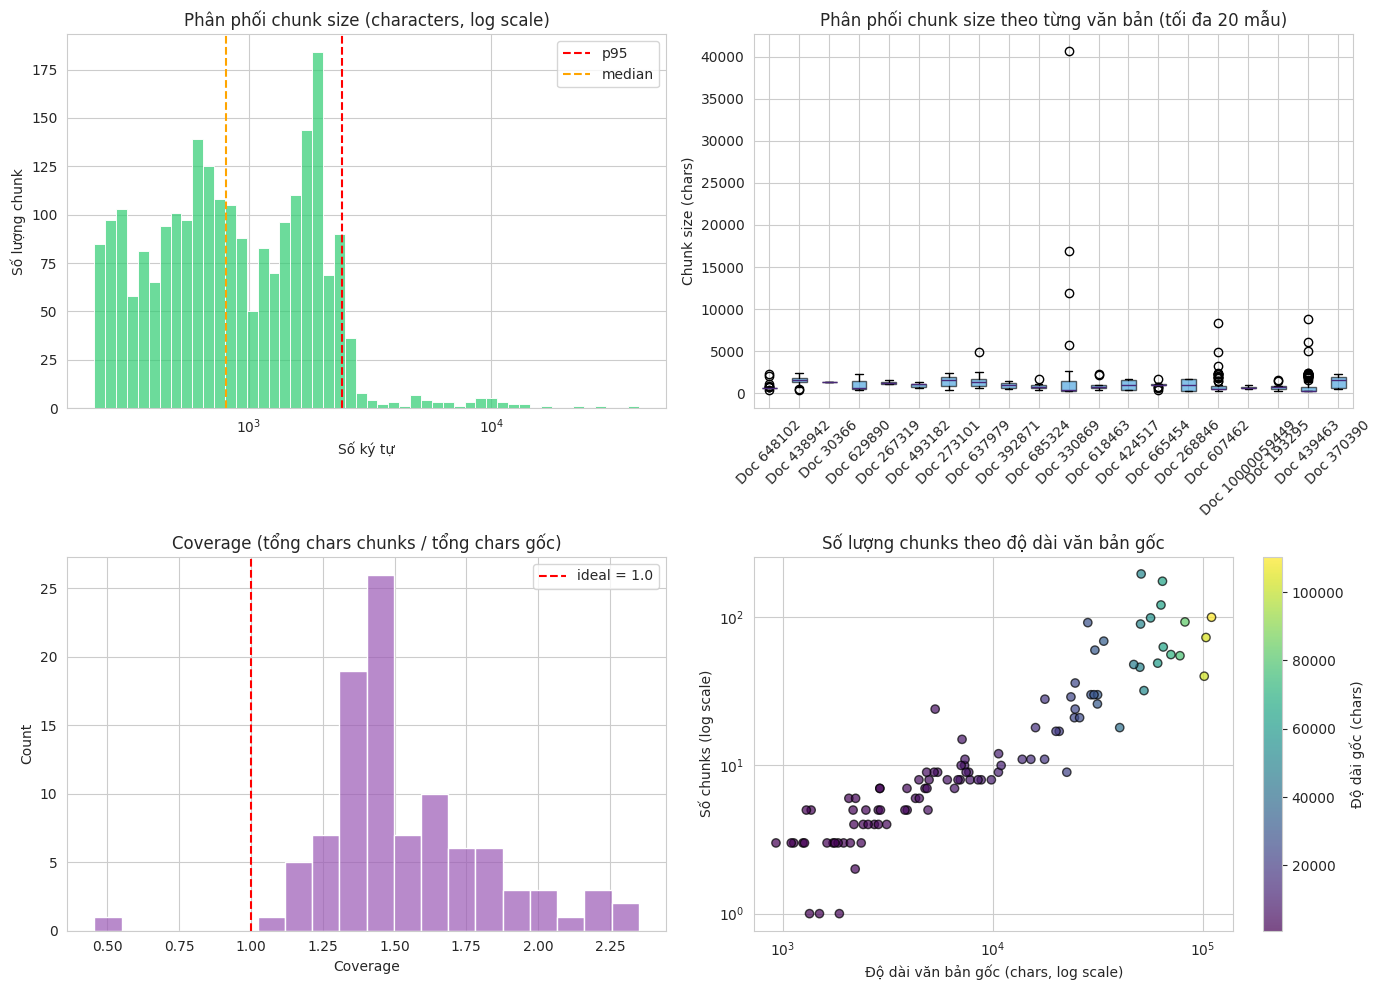

In [38]:
# Visualization phân phối chunk size và coverage
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import polars as pl

if 'results' not in globals() or len(results) == 0:
    raise ValueError("Chưa có results từ cell 2. Hãy chạy cell 2 trước.")

def _pl_content():
    for name in ("content_df", "subset_content", "content"):
        df = globals().get(name)
        if df is not None and hasattr(df, "filter"):
            return df
    raise ValueError("Không tìm thấy DataFrame Polars (content_df / subset_content). Biến 'content' đang là str?")

content_pl = _pl_content()

all_chunk_sizes = []
for res in results:
    all_chunk_sizes.extend(res.get("chunk_sizes") or [])

print(f"Số chunk thu thập được: {len(all_chunk_sizes)}")
sizes_series = pd.Series(all_chunk_sizes) if all_chunk_sizes else pd.Series(dtype=float)
if len(all_chunk_sizes):
    print("Thống kê nhanh chunk size (characters):")
    print(f"  min: {sizes_series.min()}, p50: {sizes_series.quantile(0.5):.0f}, p95: {sizes_series.quantile(0.95):.0f}, max: {sizes_series.max()}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

ax = axes[0, 0]
if len(all_chunk_sizes):
    sns.histplot(all_chunk_sizes, bins=50, log_scale=True, color="#2ecc71", alpha=0.7, ax=ax)
    ax.axvline(sizes_series.quantile(0.95), color="red", linestyle="--", label="p95")
    ax.axvline(sizes_series.quantile(0.5), color="orange", linestyle="--", label="median")
    ax.legend()
else:
    ax.text(0.5, 0.5, "Không có dữ liệu chunk size", ha="center", va="center")
ax.set_title("Phân phối chunk size (characters, log scale)")
ax.set_xlabel("Số ký tự")
ax.set_ylabel("Số lượng chunk")

ax = axes[0, 1]
valid_docs, sizes_per_doc = [], []
for res in results[:20]:
    sizes = res.get("chunk_sizes") or []
    if sizes:
        valid_docs.append(f"Doc {res['doc_id']}")
        sizes_per_doc.append(sizes)
if valid_docs:
    ax.boxplot(sizes_per_doc, labels=valid_docs, patch_artist=True,
               boxprops=dict(facecolor="#3498db", alpha=0.6))
    ax.tick_params(axis="x", rotation=45)
else:
    ax.text(0.5, 0.5, "Không đủ dữ liệu boxplot", ha="center", va="center")
ax.set_title("Phân phối chunk size theo từng văn bản (tối đa 20 mẫu)")
ax.set_ylabel("Chunk size (chars)")

ax = axes[1, 0]
if "df_results" in globals() and hasattr(df_results, "height") and df_results.height > 0:
    coverages = df_results["coverage"].to_list()
else:
    coverages = [c for c in (res.get("coverage") for res in results) if isinstance(c, (int, float))]
if coverages:
    sns.histplot(coverages, bins=20, color="#9b59b6", alpha=0.7, ax=ax)
    ax.axvline(1.0, color="red", linestyle="--", label="ideal = 1.0")
    ax.legend()
else:
    ax.text(0.5, 0.5, "Không có coverage data", ha="center", va="center")
ax.set_title("Coverage (tổng chars chunks / tổng chars gốc)")
ax.set_xlabel("Coverage")

ax = axes[1, 1]
doc_lengths, chunk_counts = [], []
for res in results:
    doc_id = res["doc_id"]
    doc_len = res.get("original_chars") or res.get("char_len")
    if doc_len is None:
        row = content_pl.filter(pl.col("id") == doc_id).select(pl.col("content").str.len_chars().alias("n")).row(0)
        doc_len = row[0] if row else 0
    doc_lengths.append(doc_len or 0)
    chunk_counts.append(res.get("total_chunks", len(res.get("chunks") or [])))

if doc_lengths:
    sc = ax.scatter(doc_lengths, chunk_counts, c=doc_lengths, cmap="viridis", alpha=0.7, edgecolors="k")
    ax.set_xscale("log")
    ax.set_yscale("log")
    plt.colorbar(sc, ax=ax, label="Độ dài gốc (chars)")
else:
    ax.text(0.5, 0.5, "Không dữ liệu", ha="center", va="center")
ax.set_title("Số lượng chunks theo độ dài văn bản gốc")
ax.set_xlabel("Độ dài văn bản gốc (chars, log scale)")
ax.set_ylabel("Số chunks (log scale)")

plt.tight_layout()
plt.show()

In [39]:
# Kiểm tra boundary integrity (kiểm tra section_path có bị cắt ngang không)
# Phân tích các chunk_type xem có sự xuất hiện hợp lệ của "Điều", "Mục", "Chương"
def check_boundary_integrity(chunks):
    """
    Duyệt qua các chunks, kiểm tra xem có chunk nào chứa nửa đầu của một section
    và chunk sau chứa nửa cuối (dấu hiệu cắt ngang) không.
    Heuristic: tìm pattern "Điều [0-9]+" ở cuối chunk và đầu chunk tiếp theo.
    """
    issues = []
    for i in range(len(chunks)-1):
        cur = chunks[i].get('content', '')
        nxt = chunks[i+1].get('content', '')
        # Kiểm tra nếu cur kết thúc bằng số + dấu cách + "Điều" thì khả năng bị cắt
        import re
        if re.search(r'\d+\s*$', cur[-100:]) and re.search(r'^Điều\s+\d+', nxt[:100]):
            issues.append((i, "Có thể bị cắt ngang điều"))
        # Tương tự cho "Mục", "Chương"
        if re.search(r'Mục\s+[0-9IVXLCDM]+\s*$', cur[-100:]) and re.search(r'^[0-9IVXLCDM]+\.', nxt[:100]):
            issues.append((i, "Có thể bị cắt ngang mục"))
    return issues

# Thu thập các vấn đề từ tất cả văn bản
all_boundary_issues = []
for res in results:
    issues = check_boundary_integrity(res['chunks'])
    if issues:
        all_boundary_issues.append((res['doc_id'], issues))

print(f"Số văn bản có dấu hiệu boundary integrity violation: {len(all_boundary_issues)}/{len(results)}")
for doc_id, issues in all_boundary_issues[:5]:  # chỉ in 5
    print(f"  Document {doc_id}: {len(issues)} vị trí nghi ngờ")

Số văn bản có dấu hiệu boundary integrity violation: 0/100


In [40]:
# Kiểm tra table integrity (tìm bảng và xem header có đi cùng không)
def has_table_issue(chunk_content, next_chunk_content):
    """
    Kiểm tra nếu chunk hiện tại kết thúc bằng header của bảng mà không có dữ liệu.
    Giả sử bảng thường có dạng: "| Header1 | Header2 |" hoặc dòng kẻ "|---|"
    """
    import re
    # Pattern kết thúc bảng: dòng kẻ hoặc header cuối cùng
    if re.search(r'(\|[-]+\|)|(Đơn\s+vị\s*tính)', chunk_content[-200:]):
        # Nếu chunk tiếp theo không bắt đầu bằng dữ liệu bảng (dòng có '|')
        if not re.search(r'^\s*\|', next_chunk_content[:200]):
            return True
    return False

table_issues = []
for res in results:
    chunks = res['chunks']
    for i in range(len(chunks)-1):
        if has_table_issue(chunks[i].get('content',''), chunks[i+1].get('content','')):
            table_issues.append((res['doc_id'], i))

print(f"Số văn bản có nghi vấn table bị tách: {len(set(d[0] for d in table_issues))}/{len(results)}")
print(f"Tổng số lần nghi ngờ: {len(table_issues)}")

Số văn bản có nghi vấn table bị tách: 0/100
Tổng số lần nghi ngờ: 0


In [41]:
# Báo cáo tóm tắt
print("=" * 60)
print("BÁO CÁO KIỂM TRA CHUNKING TRÊN 100 VĂN BẢN")
print("=" * 60)
print(f"Tổng số văn bản phân tích: {len(results)}")
print(f"Tổng số chunks tạo ra: {total_chunks}")
print(f"Coverage trung bình: {coverage_mean:.2%}")
print(f"Tỷ lệ tiny_chunk (<50 chars): {flag_counts.get('tiny_chunk',0)/total_chunks:.2%}")
print(f"Tỷ lệ oversized_chunk (>2000 chars): {flag_counts.get('oversized_chunk',0)/total_chunks:.2%}")
print(f"Tỷ lệ hard_split: {flag_counts.get('hard_split',0)/total_chunks:.2%}")
print(f"Tỷ lệ orphan_chunk: {flag_counts.get('orphan_chunk',0)/total_chunks:.2%}")
print(f"Boundary integrity violation: {len(all_boundary_issues)} văn bản có vấn đề")
print(f"Table integrity issue: {len(table_issues)} lần nghi ngờ")
print(f"Metadata propagation đúng: {metadata_ok_count}/{len(results)}")
print("=" * 60)

BÁO CÁO KIỂM TRA CHUNKING TRÊN 100 VĂN BẢN
Tổng số văn bản phân tích: 100
Tổng số chunks tạo ra: 2338
Coverage trung bình: 153.29%
Tỷ lệ tiny_chunk (<50 chars): 28.57%
Tỷ lệ oversized_chunk (>2000 chars): 0.30%
Tỷ lệ hard_split: 0.00%
Tỷ lệ orphan_chunk: 0.00%
Boundary integrity violation: 0 văn bản có vấn đề
Table integrity issue: 0 lần nghi ngờ
Metadata propagation đúng: 100/100


In [42]:
# Phân tích các chunk có kích thước > 10,000 ký tự
from collections import defaultdict

THRESHOLD_LARGE = 10000  # chars
THRESHOLD_EXTREME = 20000

large_chunks = []  # lưu (doc_id, chunk_idx, chunk_len, chunk_type, section_path, content_preview, full_content)

# Duyệt qua các kết quả đã có
for res in results:
    doc_id = res['doc_id']
    chunks = res['chunks']
    for idx, chunk in enumerate(chunks):
        # Lấy nội dung: ưu tiên 'chunk_text', fallback 'contextual_text', rồi 'content'
        content = chunk.get('chunk_text') or chunk.get('contextual_text') or chunk.get('content', '')
        if not content:
            continue
        chunk_len = len(content)
        if chunk_len > THRESHOLD_LARGE:
            chunk_type = chunk.get('chunk_type', 'unknown')
            section_path = chunk.get('section_path', '')
            # Lấy preview 1000 ký tự đầu
            preview = content[:1000]
            # Lấy toàn bộ content để phân tích sau
            large_chunks.append({
                'doc_id': doc_id,
                'chunk_idx': idx,
                'chunk_len': chunk_len,
                'chunk_type': chunk_type,
                'section_path': section_path,
                'preview': preview,
                'full_content': content
            })

print(f"Tổng số chunk > {THRESHOLD_LARGE} chars: {len(large_chunks)}")
print(f"Số chunk > {THRESHOLD_EXTREME} chars: {sum(1 for c in large_chunks if c['chunk_len'] > THRESHOLD_EXTREME)}")

# Hàm heuristic phân loại
def classify_large_chunk(content):
    """Trả về 'table/appendix', 'long_prose', hoặc 'mixed'"""
    lower = content.lower()
    lines = content.split('\n')
    pipe_lines = sum(1 for line in lines if line.strip().startswith('|'))
    dash_sep = '|---' in content or '|-' in content
    has_keyword = any(kw in lower for kw in ['bảng', 'biểu', 'phụ lục', 'table', 'appendix', 'danh mục'])
    if pipe_lines > 3 or dash_sep or has_keyword:
        return 'table/appendix'
    else:
        return 'long_prose'

# Phân loại
for chunk in large_chunks:
    chunk['category'] = classify_large_chunk(chunk['full_content'])

# Thống kê theo loại
cat_counts = defaultdict(int)
for chunk in large_chunks:
    cat_counts[chunk['category']] += 1

print("\nPhân loại chunk >10k:")
for cat, cnt in cat_counts.items():
    print(f"  {cat}: {cnt} chunk(s)")

# In chi tiết 5 chunk lớn nhất
sorted_chunks = sorted(large_chunks, key=lambda x: x['chunk_len'], reverse=True)
print("\n" + "="*80)
print("CHI TIẾT 5 CHUNK LỚN NHẤT:")
print("="*80)
for i, chunk in enumerate(sorted_chunks[:5]):
    print(f"\n--- Lớn thứ {i+1} ---")
    print(f"Doc ID: {chunk['doc_id']}, Chunk index: {chunk['chunk_idx']}")
    print(f"Kích thước: {chunk['chunk_len']} chars")
    print(f"Chunk type: {chunk['chunk_type']}")
    print(f"Section path: {chunk['section_path']}")
    print(f"Phân loại: {chunk['category']}")
    print("Preview (500 chars đầu):")
    print(chunk['preview'][:10000])
    print("...")

# Đánh giá nếu chunk 'long_prose' > 4k và >10k thì cần xem lại
problematic = [c for c in large_chunks if c['category'] == 'long_prose' and c['chunk_len'] > 4000]
if problematic:
    print(f"\n⚠️ Cảnh báo: Có {len(problematic)} chunk 'long_prose' > 4k chars (vượt ngưỡng prose hợp lý).")
    print("Các chunk này có thể do lỗi chunking, cần kiểm tra thêm:")
    for p in problematic[:3]:
        print(f"  - Doc {p['doc_id']}, size {p['chunk_len']}, section: {p['section_path']}")
else:
    print("\n✅ Không có chunk prose dài >4k, tất cả chunk lớn đều là bảng/phụ lục (hoặc không có).")

# Kiểm tra nếu có chunk nào chiếm gần như toàn bộ văn bản gốc
print("\n=== KIỂM TRA CHUNK CHIẾM PHẦN LỚN VĂN BẢN ===")
for chunk in sorted_chunks[:10]:
    doc_id = chunk['doc_id']
    original_len = subset_content.filter(pl.col('id') == doc_id)['char_len'][0]
    ratio = chunk['chunk_len'] / original_len if original_len > 0 else 0
    if ratio > 0.8:
        print(f"Doc {doc_id}: chunk {chunk['chunk_len']} / {original_len} = {ratio:.1%} - chunk gần như toàn bộ văn bản")
        print(f"  Loại: {chunk['category']}, section: {chunk['section_path']}")

Tổng số chunk > 10000 chars: 13
Số chunk > 20000 chars: 3

Phân loại chunk >10k:
  table/appendix: 12 chunk(s)
  long_prose: 1 chunk(s)

CHI TIẾT 5 CHUNK LỚN NHẤT:

--- Lớn thứ 1 ---
Doc ID: 330869, Chunk index: 19
Kích thước: 40341 chars
Chunk type: raw_table
Section path: ['Phụ lục']
Phân loại: table/appendix
Preview (500 chars đầu):
II.B DANH MỤC DỰ TOÁN BỔ SUNG CHI THƯỜNG XUYÊN NĂM 2016 ĐƠN VỊ HÀNH CHÍNH SỰ NGHIỆP CẤP THÀNH PHỐ (Từ các nguồn đã được HĐND thành phố thông qua tại kỳ họp cuối năm 2015 và các nguồn bổ sung trong năm) (Kèm theo Nghị quyết số 43/NQ-HĐND ngày 22 tháng 7 năm 2016 của Hội đồng nhân dân thành phố) ĐVT: đồng | STT | Đơn vị | Nội dung chi | Số tiền | Ghi chú (nguồn kinh phí) | | | | | | | | | TỔNG CỘNG | | 116.317.990.449 | |
| 1 | Sở Nông nghiệp và Phát triển nông thôn | | | | | | | Kinh phí phòng chống dịch bệnh trên gia súc, gia cầm và thủy sản | 5.438.023.000 | Nguồn dự phòng ngân sách 2016 | | | | Kinh phí phòng trừ chuột hại lúa Hè Thu và Thu Đông năm 20

In [43]:
# Inspect chi tiết cấu trúc chunk table/appendix (JSON output)
import json

# Lấy các chunk table/appendix lớn nhất từ large_chunks (đã có trong CELL 8)
table_chunks = [c for c in large_chunks if c['category'] == 'table/appendix']
table_chunks_sorted = sorted(table_chunks, key=lambda x: x['chunk_len'], reverse=True)

print(f"Tổng số chunk table/appendix: {len(table_chunks_sorted)}")
print("Chọn 3 chunk lớn nhất để inspect chi tiết:\n")

# Hàm in JSON đẹp với encoding utf-8
def pretty_print_chunk(chunk_info, chunk_dict):
    output = {
        "doc_id": chunk_info['doc_id'],
        "chunk_idx": chunk_info['chunk_idx'],
        "chunk_len": chunk_info['chunk_len'],
        "chunk_type": chunk_info['chunk_type'],
        "section_path": chunk_info['section_path'],
        "category": chunk_info['category'],
        "chunk_keys": list(chunk_dict.keys())
    }
    # Thêm một vài nội dung quan trọng
    for key in ['chunk_text', 'contextual_text', 'procedure_name', 'quality_flags', 'parent_id']:
        if key in chunk_dict:
            val = chunk_dict[key]
            if isinstance(val, str) and len(val) > 500:
                output[key + "_preview"] = val[:500] + "... [truncated]"
            else:
                output[key] = val
    
    print(json.dumps(output, indent=2, ensure_ascii=False))
    print("-" * 80)

# Lấy lại chunk dict từ results tương ứng
for idx, cinfo in enumerate(table_chunks_sorted[:3]):
    doc_id = cinfo['doc_id']
    chunk_idx = cinfo['chunk_idx']
    # Tìm chunk gốc trong results
    for res in results:
        if res['doc_id'] == doc_id:
            chunks = res['chunks']
            if chunk_idx < len(chunks):
                original_chunk = chunks[chunk_idx]
                print(f"\n=== CHUNK {idx+1} (doc {doc_id}, chunk {chunk_idx}) ===")
                pretty_print_chunk(cinfo, original_chunk)
                # Kiểm tra thêm: nếu là chunk type 'signature' hoặc 'raw_table' thì có giữ nguyên bảng?
                if 'chunk_text' in original_chunk:
                    sample_text = original_chunk['chunk_text']
                    # Đếm số dòng bắt đầu bằng '|' để xác nhận cấu trúc bảng
                    lines = sample_text.split('\n')
                    pipe_lines = sum(1 for line in lines if line.strip().startswith('|'))
                    print(f"📊 Kiểm tra định dạng bảng: {pipe_lines} dòng bắt đầu bằng '|' / tổng {len(lines)} dòng")
                break
    else:
        print(f"⚠️ Không tìm thấy chunk {doc_id}/{chunk_idx} trong results")

Tổng số chunk table/appendix: 12
Chọn 3 chunk lớn nhất để inspect chi tiết:


=== CHUNK 1 (doc 330869, chunk 19) ===
{
  "doc_id": 330869,
  "chunk_idx": 19,
  "chunk_len": 40341,
  "chunk_type": "raw_table",
  "section_path": [
    "Phụ lục"
  ],
  "category": "table/appendix",
  "chunk_keys": [
    "chunk_id",
    "doc_id",
    "source",
    "chunk_text",
    "contextual_text",
    "chunk_type",
    "section_path",
    "procedure_name",
    "embed",
    "keyword_index",
    "parent_id",
    "prev_chunk_id",
    "next_chunk_id",
    "token_estimate",
    "quality_flags"
  ],
  "chunk_text_preview": "II.B DANH MỤC DỰ TOÁN BỔ SUNG CHI THƯỜNG XUYÊN NĂM 2016 ĐƠN VỊ HÀNH CHÍNH SỰ NGHIỆP CẤP THÀNH PHỐ (Từ các nguồn đã được HĐND thành phố thông qua tại kỳ họp cuối năm 2015 và các nguồn bổ sung trong năm) (Kèm theo Nghị quyết số 43/NQ-HĐND ngày 22 tháng 7 năm 2016 của Hội đồng nhân dân thành phố) ĐVT: đồng | STT | Đơn vị | Nội dung chi | Số tiền | Ghi chú (nguồn kinh phí) | | | | | | | | | TỔ